# QPE

该 notebook 主要用于 QPE 迁移验证和结果对比。

- ACHN/BJT 数据迁移到 Py-ART 的处理结果验证
- `hydro_radar_echo_classification.nc` 验证 `est_rain_rate_z`、`est_rain_rate_zpoly`、`est_rain_rate_kdp`、`est_rain_rate_zkdp`、`ZtoR`、`est_rain_rate_a`、`est_rain_rate_za`、`est_rain_rate_hydro`
- Z9010：从 ``test_data/qpe`` 下 cinrad 基数据经预处理得到 Py-ART 输入；插件/CLI 输入为 ``input/Z9010_20250724192400_*.nc``

注：hydro*相关数据只有一个仰角。


## 环境准备

In [1]:
%matplotlib inline

import copy
import sys
from pathlib import Path
import os
from datetime import datetime

from cinrad_data import get_font_path
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from matplotlib.colors import BoundaryNorm, ListedColormap
from scipy.interpolate import griddata
import meteva_base as meb
import xarray as xr
import numpy as np
import pandas as pd
import pyart


NOTEBOOK_DIR = Path.cwd()   #jupyter脚本所在目录：项目根目录/radar_qpe_retrieval/nbs
QPE_DIR = NOTEBOOK_DIR.parent  #路径：项目根目录/qpe
TEST_DATA_DIR = QPE_DIR / "test_data" / "qpe"  # 测试数据总目录
CLI_INPUT_DIR = TEST_DATA_DIR / "cli_input"      # CLI 示例输入目录
CLI_OUTPUT_DIR = TEST_DATA_DIR / "cli_output"    # CLI 示例输出目录
REPO_ROOT = QPE_DIR.parent  # 项目根目录
sys.path.insert(0, str(REPO_ROOT))

from radar_qpe_retrieval.src.qpe import (
    EstimateRainRateA,
    EstimateRainRateHydro,
    EstimateRainRateKdp,
    EstimateRainRateZ,
    EstimateRainRateZA,
    EstimateRainRateZKdp,
    EstimateRainRateZPoly,
    EstimateZtoR,
)
from radar_qpe_retrieval.cli.cinrad_meb import (
    select_grid_level,
    save_meteva_grid_to_netcdf,
)


d:\workspace\pyart_nimm\venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources



## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly
## supported by the U.S. Department of Energy as part of the Atmospheric
## Radiation Measurement (ARM) Climate Research Facility, an Office of
## Science user facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



In [2]:
def masked_to_nan(data, fill_value=None, missing_value=None):
    """Convert masked arrays and known sentinel values to NaN."""
    if np.ma.isMaskedArray(data):
        array = data.astype(np.float32).filled(np.nan)
    else:
        array = np.asarray(data, dtype=np.float32)

    if fill_value is not None:
        array[array == np.float32(fill_value)] = np.nan

    if missing_value is not None:
        array[array == np.float32(missing_value)] = np.nan

    array[np.abs(array) >= np.float32(99999.0)] = np.nan
    array[array <= np.float32(-9999.0)] = np.nan
    return array

# --- cinrad 色标 + matplotlib 经纬度填色---
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable
from cinrad.visualize.utils import (
    cmap_cbar,
    cmap_plot,
    cbar_text,
    norm_cbar,
    norm_plot,
    prodname,
    unit,
)


def create_qpe_discrete_cmap():
    """返回 QPE 降水产品离散色标。"""
    bounds = [0.0, 0.1, 10.0, 25.0, 50.0, 100.0, 250.0]
    colors = [(1.0, 1.0, 1.0),
              (0.631, 0.945, 0.553),
              (0.239, 0.729, 0.239),
              (0.376, 0.722, 1.0),
              (0.0, 0.0, 1.0),
              (0.980, 0.0, 0.980)]
    labels = ["0~<0.1", "0.1~<10", "10~<25", "25~<50", "50~<100", "100~<250"]

    cmap = ListedColormap(colors, name="qpe_precip_class")
    cmap.set_bad((1.0, 1.0, 1.0, 1.0))
    cmap.set_under((1.0, 1.0, 1.0, 1.0))

    ticks = [(bounds[i] + bounds[i + 1]) / 2.0 for i in range(len(labels))]
    return cmap, BoundaryNorm(bounds, cmap.N, clip=True), ticks, labels
    

CINRAD_DTYPE_ALIASES = {
    "reflectivity": "REF",
    "corrected_reflectivity": "REF",
    "specific_differential_phase": "KDP",
    "specific_differential_phase_hv": "KDP",
    "radar_echo_classification": "HCL",
}


def resolve_cinrad_dtype(field_name: str) -> str:
    key = str(field_name).strip()
    upper = key.upper()
    if upper in norm_plot:
        return upper
    alias = CINRAD_DTYPE_ALIASES.get(key.lower())
    if alias is not None:
        return alias
    raise ValueError(f"Unknown cinrad field: {field_name}")


def _colorbar_tick_positions(cbar_norm, labels, *, plot_norm=None):
    """计算色标刻度位置；分类场用 BoundaryNorm 类别中心。"""
    labels = list(labels)
    n = len(labels)
    if n == 0:
        return None, None

    boundary_norm = plot_norm if isinstance(plot_norm, BoundaryNorm) else None
    if boundary_norm is None and isinstance(cbar_norm, BoundaryNorm):
        boundary_norm = cbar_norm
    if boundary_norm is not None:
        bounds = np.asarray(boundary_norm.boundaries, dtype=float)
        if bounds.size >= n + 1:
            tick_pos = (bounds[:n] + bounds[1 : n + 1]) / 2.0
            return tick_pos, labels
        return np.arange(n, dtype=float), labels

    vmin = float(getattr(cbar_norm, "vmin", 0.0))
    vmax = float(getattr(cbar_norm, "vmax", 1.0))
    return np.linspace(vmin, vmax, n), labels


def plot_lonlat_field(
    data,
    lon,
    lat,
    field_name,
    title,
    *,
    extent=None,
    cmap=None,
    norm=None,
    cbar_label=None,
    cbar_tick_labels=None,
    figsize=(8.0, 6.5),
):
    """用 cinrad 内置 cmap/norm 在经纬度网格上填色绘图。"""
    # 获取中文字体
    my_font = FontProperties(fname=get_font_path())

    use_cinrad_cbar = cmap is None and norm is None and cbar_tick_labels is None
    if use_cinrad_cbar:
        dtype = resolve_cinrad_dtype(field_name)
        plot_cmap = cmap_plot[dtype]
        plot_norm = norm_plot[dtype]
        cbar_cmap = cmap_cbar[dtype]
        cbar_norm = norm_cbar[dtype]
        tick_labels = cbar_text.get(dtype)
    else:
        dtype = str(field_name).strip().upper()
        plot_cmap = cmap
        plot_norm = norm
        cbar_cmap = cmap
        cbar_norm = norm
        tick_labels = cbar_tick_labels

    values = np.asarray(data, dtype=np.float32)
    lon = np.asarray(lon, dtype=np.float64)
    lat = np.asarray(lat, dtype=np.float64)
    if lon.ndim == 1 and lat.ndim == 1:
        lon_plot, lat_plot = np.meshgrid(lon, lat)
    else:
        lon_plot, lat_plot = lon, lat

    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    ax.pcolormesh(lon_plot, lat_plot, values, cmap=plot_cmap, norm=plot_norm, shading="auto")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal", adjustable="box")
    if extent is not None:
        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
    ax.grid(True, linestyle="--", linewidth=0.6, color="0.45", alpha=0.55)

    cax = make_axes_locatable(ax).append_axes("right", size="3.5%", pad=0.12)
    cbar = ColorbarBase(
        cax,
        cmap=cbar_cmap,
        norm=cbar_norm,
        orientation="vertical",
    )
    cbar.ax.tick_params(axis="both", which="both", length=0, labelsize=9)

    # 对色标标签应用中文字体
    if cbar_label is not None:
        cbar.set_label(cbar_label, fontproperties=my_font)
    elif use_cinrad_cbar:
        unit_label = unit.get(dtype, "")
        name = prodname.get(dtype, dtype)
        cbar.set_label(f"{name} ({unit_label})" if unit_label else name, fontproperties=my_font)

    if tick_labels is not None:
        tick_pos, tick_lbl = _colorbar_tick_positions(
            cbar_norm,
            tick_labels,
            plot_norm=plot_norm if not use_cinrad_cbar else None,
        )
        if tick_pos is not None:
            cbar.set_ticks(tick_pos)
            cbar.set_ticklabels([str(t) for t in tick_lbl])
            # 对色标刻度标签应用中文字体
            for label in cbar.ax.get_yticklabels():
                label.set_fontproperties(my_font)

    # 对标题应用中文字体
    fig.suptitle(title, fontproperties=my_font)
    
    return type("LonLatPlot", (), {"fig": fig, "ax": ax, "cbar": cbar})()

## 雷达数据相关处理

In [3]:
def calculate_gate_coordinates(radar, sweep=0):
    """
    计算雷达门点的经纬度坐标
    """
    if hasattr(radar, 'get_gate_lat_lon_alt'):
        lat_2d, lon_2d, _ = radar.get_gate_lat_lon_alt(sweep)
        return lon_2d, lat_2d
    elif hasattr(radar, 'gate_longitude') and hasattr(radar, 'gate_latitude'):
        return radar.gate_longitude['data'], radar.gate_latitude['data']
    else:
        # 回退计算方法
        radar_lat = radar.latitude['data'][0]
        radar_lon = radar.longitude['data'][0]
        radar_alt = radar.altitude['data'][0]
        
        azimuth = radar.get_azimuth(sweep)
        elevation = radar.get_elevation(sweep)
        ranges = radar.range['data']
        
        nrays = len(azimuth)
        ngates = len(ranges)
        
        az_grid, r_grid = np.meshgrid(azimuth, ranges, indexing='ij')
        el_grid = np.full_like(az_grid, elevation.mean())
        
        elevation_rad = np.deg2rad(el_grid)
        azimuth_rad = np.deg2rad(az_grid)
        
        s = r_grid
        z_rel = s * np.sin(elevation_rad)
        r_ground = s * np.cos(elevation_rad)
        
        x_rel = r_ground * np.sin(azimuth_rad)
        y_rel = r_ground * np.cos(azimuth_rad)
        
        R = 6371000.0
        lat0_rad = np.deg2rad(radar_lat)
        lon0_rad = np.deg2rad(radar_lon)
        
        delta_lat = y_rel / R
        delta_lon = x_rel / (R * np.cos(lat0_rad))
        
        lon_grid = np.rad2deg(lon0_rad + delta_lon)
        lat_grid = np.rad2deg(lat0_rad + delta_lat)
        
        return lon_grid, lat_grid


def get_radar_sweep_context(radar, sweep_index=0):
    """提取单扫 PPI 对比所需的索引与门点经纬度。"""
    start = int(radar.sweep_start_ray_index["data"][sweep_index])
    end = int(radar.sweep_end_ray_index["data"][sweep_index])
    sweep_slice = slice(start, end + 1)
    raw_azimuth = radar.azimuth["data"][sweep_slice].astype(np.float32)
    sort_index = np.argsort(raw_azimuth)
    gate_lon, gate_lat = calculate_gate_coordinates(radar, sweep_index)
    gate_lon = np.asarray(gate_lon, dtype=np.float64)
    gate_lat = np.asarray(gate_lat, dtype=np.float64)
    # gate_longitude 等可能为全体扫，需先切到当前 sweep，再按方位角排序
    if gate_lon.shape[0] != raw_azimuth.size:
        gate_lon = gate_lon[sweep_slice]
        gate_lat = gate_lat[sweep_slice]
    gate_lon = gate_lon[sort_index]
    gate_lat = gate_lat[sort_index]
    return {
        "sweep_slice": sweep_slice,
        "sort_index": sort_index,
        "gate_lon": gate_lon,
        "gate_lat": gate_lat,
    }


def sample_plugin_result_at_gates(plugin_result, lat_1d, lon_1d, gate_lat, gate_lon):
    """将规则经纬度网格场采样到雷达门点坐标。"""
    from scipy.interpolate import RegularGridInterpolator

    plugin_values = masked_to_nan(plugin_result.values).squeeze().astype(np.float32)
    values = np.asarray(plugin_values, dtype=np.float64)
    lat_axis = np.asarray(lat_1d, dtype=np.float64)
    lon_axis = np.asarray(lon_1d, dtype=np.float64)
    if lat_axis.size > 1 and lat_axis[0] > lat_axis[-1]:
        lat_axis = lat_axis[::-1]
        values = values[::-1, :]
    if lon_axis.size > 1 and lon_axis[0] > lon_axis[-1]:
        lon_axis = lon_axis[::-1]
        values = values[:, ::-1]
    interp = RegularGridInterpolator(
        (lat_axis, lon_axis),
        values,
        method="nearest",
        bounds_error=False,
        fill_value=np.nan,
    )
    sample_points = np.column_stack([gate_lat.ravel(), gate_lon.ravel()])
    return interp(sample_points).reshape(gate_lat.shape).astype(np.float32)


def extract_original_sweep_data(field_data, sweep_slice, sort_index):
    """从雷达二维场中提取单扫并按方位角排序后的数据。"""
    return np.asarray(
        np.ma.filled(field_data[sweep_slice][sort_index], np.nan),
        dtype=np.float32,
    )


def extract_pyart_retrieve_field(radar, field_name, sweep_slice, sort_index):
    """从 pyart.retrieve 写入 Radar 的字段中提取单扫数据（如 ZtoR 的降水率场）。"""
    if field_name not in radar.fields:
        raise KeyError(
            f"Field '{field_name}' not in radar.fields. Available: {list(radar.fields)}"
        )
    return extract_original_sweep_data(
        radar.fields[field_name]["data"],
        sweep_slice,
        sort_index,
    )


## 单个 ACHN 和 BJT 个例

本节组织方式如下：

- 单元 1：读取 ACHN/BJT 数据，分别调用原 Py-ART 方法和迁移后插件方法
- 单元 2：绘制原始 ACHN_CREF 反射率场
- 单元 3：绘制 BJT 实况降水场
- 单元 4：绘制原算法与插件结果的差值图，并统计 z、zpoly、ZtoR 公式参考结果


### 数据处理函数及绘图函数

In [4]:
class PyArtGridAdapter:
    """用于调用 Py-ART QPE 方法的轻量适配器。"""

    def __init__(self, data: np.ndarray, field_name: str = "reflectivity"):
        self.fields = {
            field_name: {
                "data": np.ma.masked_invalid(np.asarray(data, dtype=np.float32))
            }
        }

    def check_field_exists(self, field_name: str):
        if field_name not in self.fields:
            raise KeyError(f"Field not available: {field_name}")

    def add_field(self, field_name: str, field_dict: dict, replace_existing: bool = False):
        if (not replace_existing) and (field_name in self.fields):
            raise ValueError(f"Field already exists: {field_name}")
        if "data" not in field_dict:
            raise KeyError("field_dict must contain 'data'")

        data_in = field_dict["data"]
        if np.ma.isMaskedArray(data_in):
            data_ma = np.ma.array(data_in, dtype=np.float32, copy=True)  # 保留原 mask
            data_ma = np.ma.masked_invalid(data_ma)
        else:
            data_ma = np.ma.masked_invalid(np.asarray(data_in, dtype=np.float32))

        out = dict(field_dict)
        out["data"] = data_ma
        self.fields[field_name] = out


def _infer_datetime_from_filename(file_path: Path) -> np.datetime64:
    """从文件名中推断时间（格式如 YYYYMMDD_HHMMSS）。"""
    text = file_path.stem
    digits = ''.join(ch for ch in text if ch.isdigit())
    if len(digits) >= 14:
        digits = digits[-14:]
        return np.datetime64(
            f"{digits[:4]}-{digits[4:6]}-{digits[6:8]}T{digits[8:10]}:{digits[10:12]}:{digits[12:14]}"
        )
    return np.datetime64("1970-01-01T00:00:00")


def preprocess_achn_to_meb_nc(file_path: Path, output_dir: Path) -> Path:
    """将 ACHN CREF 数据转换为 meb 6D netCDF 格式，落盘后返回处理后的数据。"""
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / file_path.name

    # 读取网格数据
    grid_data = meb.read_griddata_from_nc(
        str(file_path),
        value_name="cref",
        level_dim="lev",
    )

    # 在数据预处理阶段统一时间/预报时效格式，不在算法内部处理
    if not np.issubdtype(grid_data["time"].dtype, np.datetime64):
        grid_data = grid_data.assign_coords(time=np.array([_infer_datetime_from_filename(file_path)], dtype="datetime64[s]"))
    if grid_data["dtime"].dtype != np.int32:
        grid_data = grid_data.assign_coords(dtime=grid_data["dtime"].values.astype(np.int32))

    # 在写入预处理文件前清理哨兵值  
    grid_data = grid_data.astype(np.float32, copy=False)
    clean = np.asarray(grid_data.values, dtype=np.float32).copy()
    # 处理填充值
    fill_value = grid_data.attrs.get("_FillValue", None)
    if fill_value is not None:
        clean[clean == np.float32(fill_value)] = np.nan
    # 清理异常值
    clean[np.abs(clean) >= np.float32(1.0e20)] = np.nan
    clean[clean <= np.float32(-1000.0)] = np.nan

    # 更新数据
    grid_data = grid_data.copy()
    grid_data.values = clean
    grid_data.name = "cref"
    # 在输出 netCDF 中保留 NaN，而不是编码为大的填充值
    ds_out = grid_data.to_dataset(name=grid_data.name)
    ds_out.to_netcdf(str(output_path), encoding={grid_data.name: {"_FillValue": None}})
    return grid_data
    

def plot_latlon_comparison(title: str, original: np.ndarray, migrated: np.ndarray, lat: np.ndarray, lon: np.ndarray):
    """绘制原始结果、迁移结果以及差值的经纬度对比图，使用表1离散降水色标。"""
    # 获取表1离散降水色标
    qpe_cmap, qpe_norm, qpe_ticks, qpe_tick_labels = create_qpe_discrete_cmap()
    # 获取中文字体
    fp = FontProperties(fname=get_font_path())
    
    difference = migrated - original
    
    vmin, vmax = qpe_norm.boundaries[0], qpe_norm.boundaries[-1]

    finite_diff = difference[np.isfinite(difference)]
    dmax = float(np.nanpercentile(np.abs(finite_diff), 99.0)) if finite_diff.size else 1.0
    if np.isclose(dmax, 0.0):
        dmax = 1.0

    # 为避免绘制点过多，按需对经纬度网格进行抽样
    max_plot_points = 1500
    row_step = max(1, int(np.ceil(original.shape[0] / max_plot_points)))
    col_step = max(1, int(np.ceil(original.shape[1] / max_plot_points)))
    lat_plot = lat[::row_step]
    lon_plot = lon[::col_step]
    original_plot = original[::row_step, ::col_step]
    migrated_plot = migrated[::row_step, ::col_step]
    difference_plot = difference[::row_step, ::col_step]

    fig, axes = plt.subplots(1, 3, figsize=(24, 7), constrained_layout=True, dpi=140)

    # 子图1: 原始结果 - 使用表1离散降水色标
    im0 = axes[0].pcolormesh(lon_plot, lat_plot, original_plot, 
                            shading="auto", cmap=qpe_cmap, norm=qpe_norm)
    axes[0].set_title(f"原始 Py-ART: {title}", fontproperties=fp)
    axes[0].set_xlabel("Longitude")
    axes[0].set_ylabel("Latitude")
    cbar0 = fig.colorbar(im0, ax=axes[0], shrink=0.9, extend="max")
    cbar0.set_ticks(qpe_ticks)
    cbar0.set_ticklabels(qpe_tick_labels)
    cbar0.set_label("降水量 (mm/h)", fontproperties=fp)

    # 子图2: 迁移后结果 - 使用表1离散降水色标
    im1 = axes[1].pcolormesh(lon_plot, lat_plot, migrated_plot, 
                            shading="auto", cmap=qpe_cmap, norm=qpe_norm)
    axes[1].set_title(f"修改后算法: {title}", fontproperties=fp)
    axes[1].set_xlabel("Longitude")
    axes[1].set_ylabel("Latitude")
    cbar1 = fig.colorbar(im1, ax=axes[1], shrink=0.9, extend="max")
    cbar1.set_ticks(qpe_ticks)
    cbar1.set_ticklabels(qpe_tick_labels)
    cbar1.set_label("降水量 (mm/h)", fontproperties=fp)

    # 子图3: 差值图 - 仍使用coolwarm颜色映射
    im2 = axes[2].pcolormesh(lon_plot, lat_plot, difference_plot, 
                            shading="auto", cmap="coolwarm", vmin=-dmax, vmax=dmax)
    axes[2].set_title("差值图: 迁移后 - 原始", fontproperties=fp)
    axes[2].set_xlabel("Longitude")
    axes[2].set_ylabel("Latitude")
    cbar2 = fig.colorbar(im2, ax=axes[2], shrink=0.9)
    cbar2.set_label("差值 (mm/h)", fontproperties=fp)

    mae = float(np.nanmean(np.abs(difference)))
    max_abs = float(np.nanmax(np.abs(difference)))
    fig.suptitle(f"{title} | MAE={mae:.6g}, MaxAbs={max_abs:.6g}", fontsize=13, fontproperties=fp)
    plt.show()

    return {
        "method": title,
        "mae": mae,
        "max_abs": max_abs,
        "vmin": vmin,
        "vmax": vmax
    }


### 数据预处理

In [5]:
achn_file = TEST_DATA_DIR / "ACHN_CREF000_20240612_070000.nc"  # 原折射率数据路径
bjt_file = TEST_DATA_DIR / "BJT_24061215.000.nc"   # 降水实况数据路径

achn_grid = preprocess_achn_to_meb_nc(achn_file, CLI_INPUT_DIR)
achn_lat = achn_grid["lat"].values.astype(np.float64)
achn_lon = achn_grid["lon"].values.astype(np.float64)

with xr.open_dataset(bjt_file) as bjt_ds:
    bjt_raw = bjt_ds["data0"].isel(member=0, level=0, time=0, dtime=0).astype(np.float32)
    lat_min, lat_max = float(np.min(achn_lat)), float(np.max(achn_lat))
    lon_min, lon_max = float(np.min(achn_lon)), float(np.max(achn_lon))
    bjt_cropped = bjt_raw.sel(
        lat=slice(lat_min, lat_max),
        lon=slice(lon_min, lon_max),
    )
#构建Radar对象作为原方法输入
original_radar = PyArtGridAdapter(np.asarray(achn_grid.values).squeeze(), field_name="reflectivity")

datetime64 values must have a unit specified
datetime64 values must have a unit specified


### 方法调用

In [6]:
# 原方法调用
rain_rate_z = pyart.retrieve.est_rain_rate_z(
    original_radar,
    alpha=0.0376,
    beta=0.6112,
    refl_field="reflectivity",
)
rain_rate_zpoly = pyart.retrieve.est_rain_rate_zpoly(
    original_radar,
    refl_field="reflectivity",
)
pyart.retrieve.ZtoR(
    original_radar,
    ref_field="reflectivity",
    a=300.0,
    b=1.4,
    save_name="NWS_primary_prate",
)

# 插件算法调用
plugin_z = EstimateRainRateZ(alpha=0.0376, beta=0.6112).process(refl=achn_grid)
plugin_zpoly = EstimateRainRateZPoly().process(refl=achn_grid)
plugin_ztor = EstimateZtoR(a=300.0, b=1.4).process(refl=achn_grid)

achn_cref_data = np.asarray(achn_grid.values).squeeze().astype(np.float32)
bjt_lat = bjt_cropped["lat"].values.astype(np.float64)
bjt_lon = bjt_cropped["lon"].values.astype(np.float64)
bjt_observed = np.asarray(bjt_cropped.values).squeeze().astype(np.float32)
bjt_observed[bjt_observed >= 99999.0] = np.nan
bjt_observed[bjt_observed < 0.0] = np.nan

rain_rate_z_data = np.asarray(np.ma.filled(rain_rate_z["data"], np.nan)).squeeze().astype(np.float32)
rain_rate_zpoly_data = np.asarray(np.ma.filled(rain_rate_zpoly["data"], np.nan)).squeeze().astype(np.float32)
rain_rate_ztor_data = np.asarray(
    np.ma.filled(original_radar.fields["NWS_primary_prate"]["data"], np.nan),
    dtype=np.float32,
)
plugin_z_data = masked_to_nan(plugin_z.values).squeeze().astype(np.float32)
plugin_zpoly_data = masked_to_nan(plugin_zpoly.values).squeeze().astype(np.float32)
plugin_ztor_data = masked_to_nan(plugin_ztor.values).squeeze().astype(np.float32)

bjt_valid = bjt_observed[np.isfinite(bjt_observed)]
if bjt_valid.size:
    bjt_vmin = float(np.nanpercentile(bjt_valid, 1.0))
    bjt_vmax = float(np.nanpercentile(bjt_valid, 99.0))
    if np.isclose(bjt_vmin, bjt_vmax):
        bjt_vmin = float(np.nanmin(bjt_valid))
        bjt_vmax = float(np.nanmax(bjt_valid))
        if np.isclose(bjt_vmin, bjt_vmax):
            bjt_vmax = bjt_vmin + 1.0
else:
    bjt_vmin, bjt_vmax = 0.0, 1.0


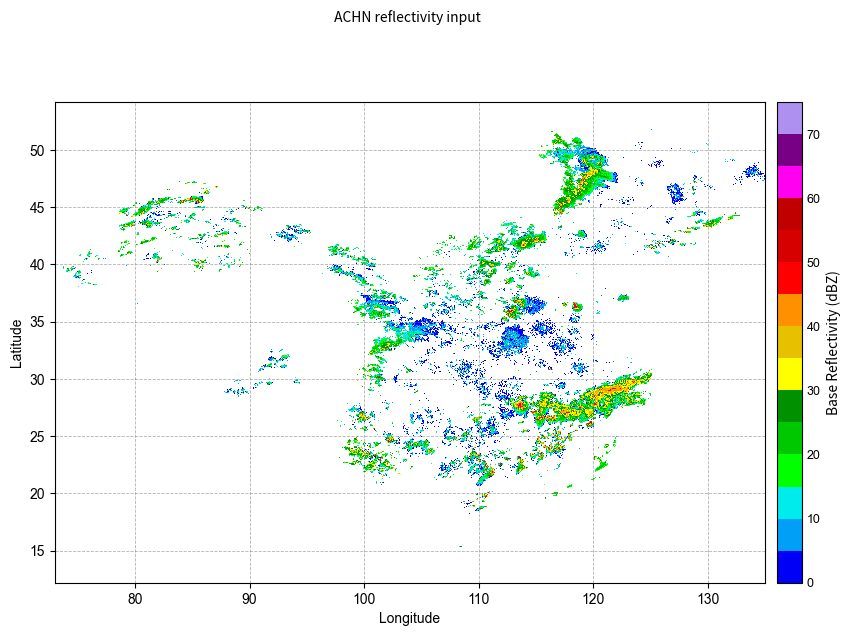

In [7]:
# 反射率输入数据图
ref_plot = plot_lonlat_field(
    achn_cref_data,
    achn_lon,
    achn_lat,
    'REF',
    ' ACHN reflectivity input',
)
display(ref_plot.fig)
plt.close(ref_plot.fig)

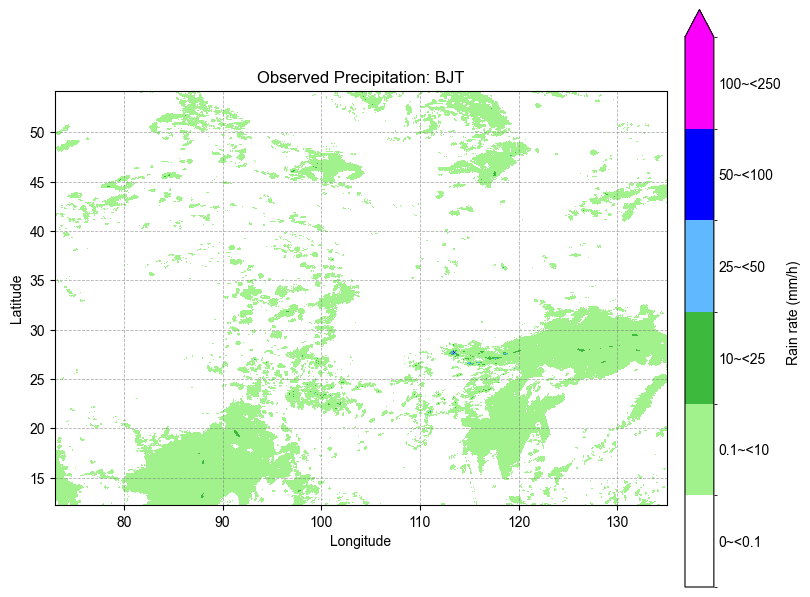

In [8]:
# 降水实况数据
qpe_cmap, qpe_norm, qpe_ticks, qpe_tick_labels = create_qpe_discrete_cmap()

fig, ax = plt.subplots(figsize=(8.0, 6.5), constrained_layout=True)
image = ax.pcolormesh(
    bjt_lon,
    bjt_lat,
    bjt_observed,
    shading='auto',
    cmap=qpe_cmap,
    norm=qpe_norm,
)
ax.set_xlim(float(np.min(achn_lon)), float(np.max(achn_lon)))
ax.set_ylim(float(np.min(achn_lat)), float(np.max(achn_lat)))
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_aspect('equal', adjustable='box')
ax.grid(True, linestyle='--', linewidth=0.6, color='0.45', alpha=0.55)
ax.set_title('Observed Precipitation: BJT')

cbar = fig.colorbar(image, ax=ax, extend='max', shrink=0.9, pad=0.03)
cbar.set_ticks(qpe_ticks)
cbar.set_ticklabels(qpe_tick_labels)
cbar.set_label('Rain rate (mm/h)')
cbar.ax.tick_params(length=0)

plt.show()


### 结果对比

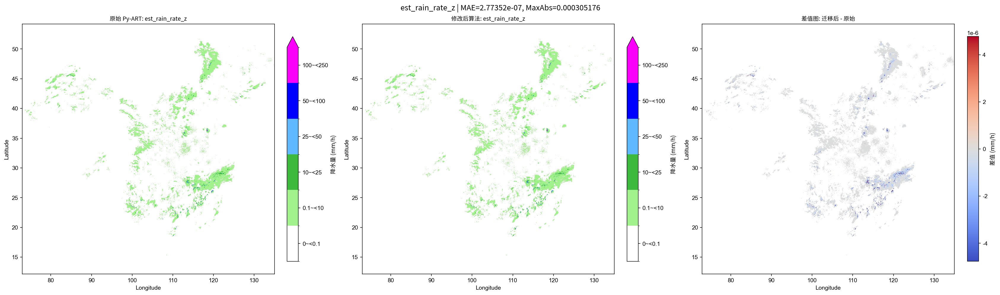

{'method': 'est_rain_rate_z',
 'mae': 2.7735163143915997e-07,
 'max_abs': 0.00030517578125,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [9]:
plot_latlon_comparison(
    title="est_rain_rate_z",
    original=rain_rate_z_data,
    migrated=plugin_z_data,
    lat=achn_lat,
    lon=achn_lon,
)

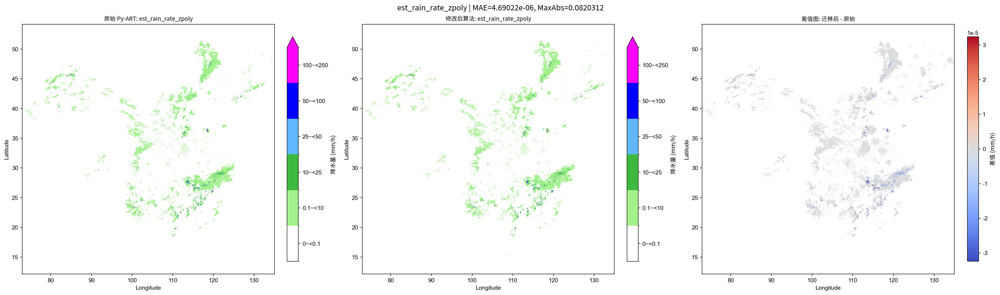

{'method': 'est_rain_rate_zpoly',
 'mae': 4.690215519076446e-06,
 'max_abs': 0.08203125,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [10]:
plot_latlon_comparison(
    title="est_rain_rate_zpoly",
    original=rain_rate_zpoly_data,
    migrated=plugin_zpoly_data,
    lat=achn_lat,
    lon=achn_lon,
)

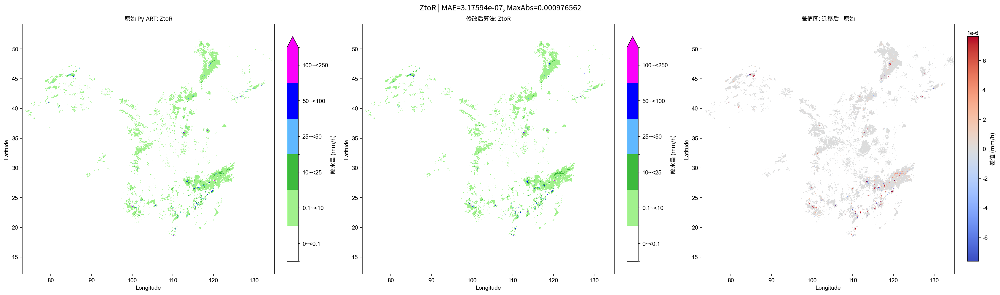

{'method': 'ZtoR',
 'mae': 3.175942993038916e-07,
 'max_abs': 0.0009765625,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [11]:
plot_latlon_comparison(
    title="ZtoR",
    original=rain_rate_ztor_data,
    migrated=plugin_ztor_data,
    lat=achn_lat,
    lon=achn_lon,
)

## Z9010 双偏振单站数据

从 ``test_data/qpe`` 目录下的 双偏振雷达基数据读取（``Z_RADR_I_Z9010_20250724192400_O_DOR_SAD_CAP_FMT.bin.bz2``），数据处理流程可分为两个分支：

- **原算法 (Py-ART)**：``load_cinrad_pyart_radar`` → 内存 ``z9010_radar`` / ``composite_reflectivity``
- **迁移插件 / CLI**：``cinrad get_data`` + ``grid_2d`` / ``quick_cr`` → meteva 体扫 NC（``Z9010_20250724192400_*.nc``）
- **输入数据图**：cinrad ``get_data`` / ``quick_cr`` + ``cinrad.visualize.PPI``

说明：旧版 ``Z9010_20260512_000600.nc`` 仍保留在同目录，本段验证改用 20250724 体扫基数据。


In [12]:
def plot_radar_lonlat_comparison(
    title: str,
    original: np.ndarray,
    migrated: np.ndarray,
    gate_lat: np.ndarray,
    gate_lon: np.ndarray,
    *,
    extent=None,
):
    """按雷达门真实经纬度绘制原算法、迁移算法和差值图，使用表1离散降水色标。"""
    # 获取表1离散降水色标
    qpe_cmap, qpe_norm, qpe_ticks, qpe_tick_labels = create_qpe_discrete_cmap()
    # 获取中文字体
    fp = FontProperties(fname=get_font_path())
    difference = migrated - original
    
    vmin, vmax = qpe_norm.boundaries[0], qpe_norm.boundaries[-1]

    finite_diff = difference[np.isfinite(difference)]
    dmax = float(np.nanpercentile(np.abs(finite_diff), 99.0)) if finite_diff.size else 1.0
    if np.isclose(dmax, 0.0):
        dmax = 1.0

    if extent is not None:
        xlim = (extent[0], extent[1])
        ylim = (extent[2], extent[3])
    else:
        valid_mask = np.isfinite(original) | np.isfinite(migrated)
        if np.any(valid_mask):
            valid_lon = gate_lon[valid_mask]
            valid_lat = gate_lat[valid_mask]
            lon_min = float(np.nanmin(valid_lon))
            lon_max = float(np.nanmax(valid_lon))
            lat_min = float(np.nanmin(valid_lat))
            lat_max = float(np.nanmax(valid_lat))
            lon_pad = max((lon_max - lon_min) * 0.05, 0.05)
            lat_pad = max((lat_max - lat_min) * 0.05, 0.05)
        else:
            lon_min = float(np.nanmin(gate_lon))
            lon_max = float(np.nanmax(gate_lon))
            lat_min = float(np.nanmin(gate_lat))
            lat_max = float(np.nanmax(gate_lat))
            lon_pad = 0.0
            lat_pad = 0.0
        xlim = (lon_min - lon_pad, lon_max + lon_pad)
        ylim = (lat_min - lat_pad, lat_max + lat_pad)

    fig, axes = plt.subplots(1, 3, figsize=(24, 7), constrained_layout=True)
    
    # 子图1: 原始结果 - 使用表1离散降水色标
    im0 = axes[0].pcolormesh(gate_lon, gate_lat, original, 
                            shading="auto", cmap=qpe_cmap, norm=qpe_norm)
    axes[0].set_title(f"原始 Py-ART: {title}", fontproperties=fp)
    axes[0].set_xlabel("Longitude")
    axes[0].set_ylabel("Latitude")
    axes[0].set_aspect("equal", "box")
    axes[0].set_xlim(*xlim)
    axes[0].set_ylim(*ylim)
    cbar0 = fig.colorbar(im0, ax=axes[0], shrink=0.9, extend="max")
    cbar0.set_ticks(qpe_ticks)
    cbar0.set_ticklabels(qpe_tick_labels)
    cbar0.set_label("降水量 (mm/h)", fontproperties=fp)

    # 子图2: 迁移后结果 - 使用表1离散降水色标
    im1 = axes[1].pcolormesh(gate_lon, gate_lat, migrated, 
                            shading="auto", cmap=qpe_cmap, norm=qpe_norm)
    axes[1].set_title(f"修改后插件: {title}", fontproperties=fp)
    axes[1].set_xlabel("Longitude")
    axes[1].set_ylabel("Latitude")
    axes[1].set_aspect("equal", "box")
    axes[1].set_xlim(*xlim)
    axes[1].set_ylim(*ylim)
    cbar1 = fig.colorbar(im1, ax=axes[1], shrink=0.9, extend="max")
    cbar1.set_ticks(qpe_ticks)
    cbar1.set_ticklabels(qpe_tick_labels)
    cbar1.set_label("降水量 (mm/h)", fontproperties=fp)

    # 子图3: 差值图 - 仍使用coolwarm颜色映射
    im2 = axes[2].pcolormesh(gate_lon, gate_lat, difference, 
                            shading="auto", cmap="coolwarm", vmin=-dmax, vmax=dmax)
    axes[2].set_title("差值: 修改后插件 - 原始 Py-ART", fontproperties=fp)
    axes[2].set_xlabel("Longitude")
    axes[2].set_ylabel("Latitude")
    axes[2].set_aspect("equal", "box")
    axes[2].set_xlim(*xlim)
    axes[2].set_ylim(*ylim)
    for _ax in axes:
        _ax.grid(True, linestyle="--", linewidth=0.6, color="0.45", alpha=0.55)
    cbar2 = fig.colorbar(im2, ax=axes[2], shrink=0.9)
    cbar2.set_label("差值 (mm/h)", fontproperties=fp)

    valid = (
        np.isfinite(original) & np.isfinite(migrated)
        & (original >= 0) & (migrated >= 0)
    )
    diff_valid = difference[valid]
    mae = float(np.nanmean(np.abs(diff_valid))) if diff_valid.size else np.nan
    p99_abs = float(np.nanpercentile(np.abs(diff_valid), 99.0)) if diff_valid.size else np.nan
    max_abs = float(np.nanmax(np.abs(diff_valid))) if diff_valid.size else np.nan
    fig.suptitle(
        f"{title} | MAE={mae:.6g}, P99={p99_abs:.6g}, MaxAbs(valid)={max_abs:.6g}",
        fontsize=13,
        fontproperties=fp,
    )
    plt.show()
    
    return {
        "method": title,
        "mae": mae,
        "max_abs": max_abs,
        "p99_abs": p99_abs,
        "vmin": vmin,
        "vmax": vmax
    }


### 数据预处理

原方法输入：使用cinrad库读取雷达基数据，然后通过cinrad库方法转换为pyart库的输入Radar，并做修复处理。
修改后算法输入：使用cinrad库读取雷达基数据，得到xarray.Dataset类型数据，据此做相关处理获得xr.DataArray输入。

In [ ]:
# --- Z9010：cinrad→meteva NC（迁移/CLI）+ Py-ART Radar（原算法）---
import cinrad

from radar_qpe_retrieval.cli.cinrad_pyart_prep import (
    apply_latlon_mask_to_pyart_radar,
    fill_pyart_radar_from_quick_cr,
    load_cinrad_pyart_radar,
)
from radar_qpe_retrieval.cli.cinrad_meb import (
    apply_cr_dataset_gate_mask,  # 组合反射率掩膜应用，用于后续Radar值覆盖
    apply_cref_quality_gatefilter,  # 组合反射率过滤器应用
    apply_meteva_gate_mask,  # 网格数据掩膜应用
    build_cref_qc_aux_grids_from_cinrad,
    cinrad_cr_to_meteva_grid,  # 组合反射率数据转换为网格格式
    cinrad_dtype_to_meteva_volume,
    meteva_grid_plot_arrays,
)
# ===== 1) 基础路径与实验参数 =====
z9010_file = TEST_DATA_DIR / 'Z_RADR_I_Z9010_20250724192400_O_DOR_SAD_CAP_FMT.bin.bz2'
z9010_case_id = 'Z9010_20250724192400'

z9010_meb_range_km = 300

# GridGateFilter：低仰角 REF + RHO + CREF 阈值（与 save/plugin/QPE 一致）
z9010_qc_min_refl_dbz = 15.0
z9010_qc_min_rho = 0.85
z9010_qc_min_cref_dbz = 15.0
z9010_qc_max_dbz = 80.0
z9010_qc_max_low_tilt_deg = 2.0

sweep_index = 0  #使用仰角层索引

cli_input_dir = CLI_INPUT_DIR
cli_input_dir.mkdir(parents=True, exist_ok=True)

# 网格数据保存路径（保存 QC 后产品）
kdp_volume_file = cli_input_dir / f"{z9010_case_id}_kdp_volume.nc"
refl_volume_file = cli_input_dir / f"{z9010_case_id}_refl_volume.nc"
cref_meb_file = cli_input_dir / f"{z9010_case_id}_cref.nc"

# ===== 2) 读取 cinrad 基数据并转换为 Py-ART Radar =====
z9010_cinrad_file, z9010_radar = load_cinrad_pyart_radar(  # z9010_cinrad_file为cinrad库读取的雷达基数据
    z9010_file, radius=460, prepare=True,
)

z9010_station_id = 'Z9010'
z9010_scan_time_label = pd.to_datetime(z9010_cinrad_file.scantime).strftime('%Y-%m-%d %H:%M:%S')
z9010_input_meta = f'站号 {z9010_station_id}    {z9010_scan_time_label}'

kdp_field = 'specific_differential_phase'
refl_field = 'reflectivity'

# ===== 3) 构建 KDP/REF 体扫网格（插件算法与 CLI示例 共用输入） =====
kdp_volume_grid, _ = cinrad_dtype_to_meteva_volume(
    z9010_cinrad_file,
    'KDP',
    range_km=z9010_meb_range_km,
    resolution=(1000, 1000),
)

refl_volume_grid, _ = cinrad_dtype_to_meteva_volume(
    z9010_cinrad_file,
    'REF',
    range_km=z9010_meb_range_km,
    resolution=(1000, 1000),
)

# 第一层仰角度数
z9010_elev_deg = float(kdp_volume_grid.coords["level"].values[sweep_index])
# ===== 4) 提取当前 sweep 的门点上下文（原方法对比统一使用） =====
sweep_ctx = get_radar_sweep_context(z9010_radar, sweep_index)
sweep_slice = sweep_ctx['sweep_slice']
sort_index = sweep_ctx['sort_index']
gate_lon = sweep_ctx['gate_lon']
gate_lat = sweep_ctx['gate_lat']

# ===== 5) 计算 CREF 与 QC 掩膜（低仰角 REF + RHO + CREF 阈值） =====
_z9010_cr_list = list(z9010_cinrad_file.iter_tilt(z9010_meb_range_km, 'REF'))
z9010_cr_ds = cinrad.calc.quick_cr(_z9010_cr_list, resolution=(1000, 1000))  # 组合反射率
z9010_cr_ds['CR'].attrs['units'] = 'dBZ'
# 转换为网格类型
cref_griddata_raw = cinrad_cr_to_meteva_grid(z9010_cr_ds, cinrad_file=z9010_cinrad_file)

z9010_refl_low, z9010_rho_low, z9010_low_tilt_idx = build_cref_qc_aux_grids_from_cinrad(
    z9010_cinrad_file,
    cref_griddata_raw,
    range_km=z9010_meb_range_km,
    max_low_tilt_deg=z9010_qc_max_low_tilt_deg,
)
cref_griddata, z9010_gate_included = apply_cref_quality_gatefilter(
    cref_griddata_raw,
    refl_low=z9010_refl_low,
    rho_low=z9010_rho_low,
    min_refl_dbz=z9010_qc_min_refl_dbz,
    min_rho=z9010_qc_min_rho,
    min_cref_dbz=z9010_qc_min_cref_dbz,
    max_dbz=z9010_qc_max_dbz,
)
# 体扫：同一 2D 掩膜作用于全部 level，再落盘（CLI 与插件读 QC 后 NC）
kdp_volume_grid = apply_meteva_gate_mask(kdp_volume_grid, z9010_gate_included)
refl_volume_grid = apply_meteva_gate_mask(refl_volume_grid, z9010_gate_included)
save_meteva_grid_to_netcdf(kdp_volume_grid, output_path=str(kdp_volume_file), show=False)
save_meteva_grid_to_netcdf(refl_volume_grid, output_path=str(refl_volume_file), show=False)
save_meteva_grid_to_netcdf(cref_griddata, output_path=str(cref_meb_file), show=False)
print(
    'QC saved (all levels masked):',
    f'low_tilt_idx={z9010_low_tilt_idx}',
    f'kept={float(z9010_gate_included.mean()):.3f}',
    kdp_volume_file.name,
    refl_volume_file.name,
    cref_meb_file.name,
)

# ===== 6) 选取当前 sweep，用于输入场展示与算法对比 =====
kdp_griddata = select_grid_level(kdp_volume_grid, sweep_index)
refl_griddata = select_grid_level(refl_volume_grid, sweep_index)
print('CLI/plugin inputs (QC):', kdp_volume_file.name, refl_volume_file.name, cref_meb_file.name)

kdp_data, kdp_lon_2d, kdp_lat_2d, target_lon, target_lat = meteva_grid_plot_arrays(
    kdp_griddata,
)
refl_data, refl_lon_2d, refl_lat_2d, _, _ = meteva_grid_plot_arrays(refl_griddata)
cref_data, cref_lon_2d, cref_lat_2d, cref_target_lon, cref_target_lat = meteva_grid_plot_arrays(
    cref_griddata,
)

z9010_compare_extent = [
    float(target_lon.min()),
    float(target_lon.max()),
    float(target_lat.min()),
    float(target_lat.max()),
]

# ===== 7) 将同一 QC 掩膜同步到 Py-ART Radar 与 quick_cr，确保原/新方法输入一致 =====
z9010_cr_ds_qc = apply_cr_dataset_gate_mask(z9010_cr_ds, z9010_gate_included)
_z9010_cr_lat = np.asarray(z9010_cr_ds['latitude'].values, dtype=np.float64)
_z9010_cr_lon = np.asarray(z9010_cr_ds['longitude'].values, dtype=np.float64)

# 原算法 Radar：与 meteva/CR 共用同一 2D 掩膜（门点经纬度采样）
apply_latlon_mask_to_pyart_radar(
    z9010_radar,
    z9010_gate_included,
    _z9010_cr_lon,
    _z9010_cr_lat,
)

z9010_cref_radar = pyart.retrieve.composite_reflectivity(z9010_radar, field=refl_field)
fill_pyart_radar_from_quick_cr(
    z9010_cr_ds_qc, z9010_cref_radar, field_name='composite_reflectivity', sweep_index=0,
)

z9010_cref_ctx = get_radar_sweep_context(z9010_cref_radar, 0)
z9010_cref_gate_lon = z9010_cref_ctx['gate_lon']
z9010_cref_gate_lat = z9010_cref_ctx['gate_lat']
z9010_cref_sweep_slice = z9010_cref_ctx['sweep_slice']
z9010_cref_sort_index = z9010_cref_ctx['sort_index']


QC saved (all levels masked): low_tilt_idx=0 kept=0.113 Z9010_20250724192400_kdp_volume.nc Z9010_20250724192400_refl_volume.nc Z9010_20250724192400_cref.nc
CLI/plugin inputs (QC): Z9010_20250724192400_kdp_volume.nc Z9010_20250724192400_refl_volume.nc Z9010_20250724192400_cref.nc


### Z9010 输入场

掩膜为：低仰角 REF + RHO + CREF 阈值。

REF小于15dZB的部分会被过滤，RHO小于0.85的部分会被过滤，CREF小于15或大于80的部分会被过滤。反射率和KPD数据使用掩码与CREF相同。


掩码过滤前数据图

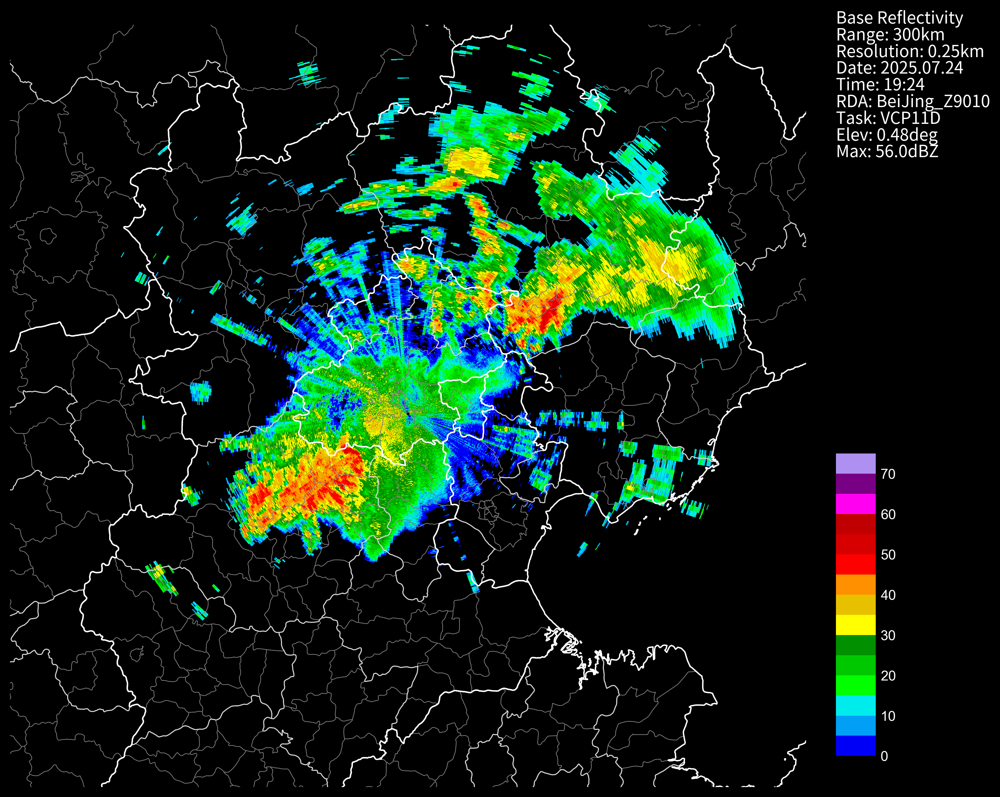

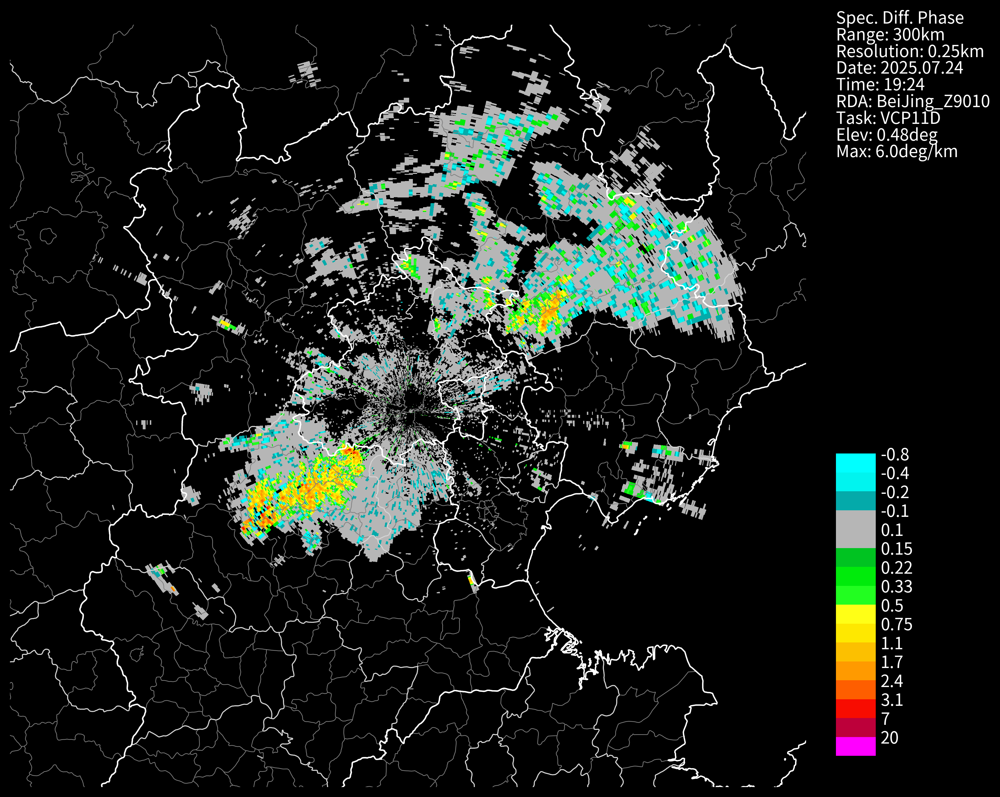

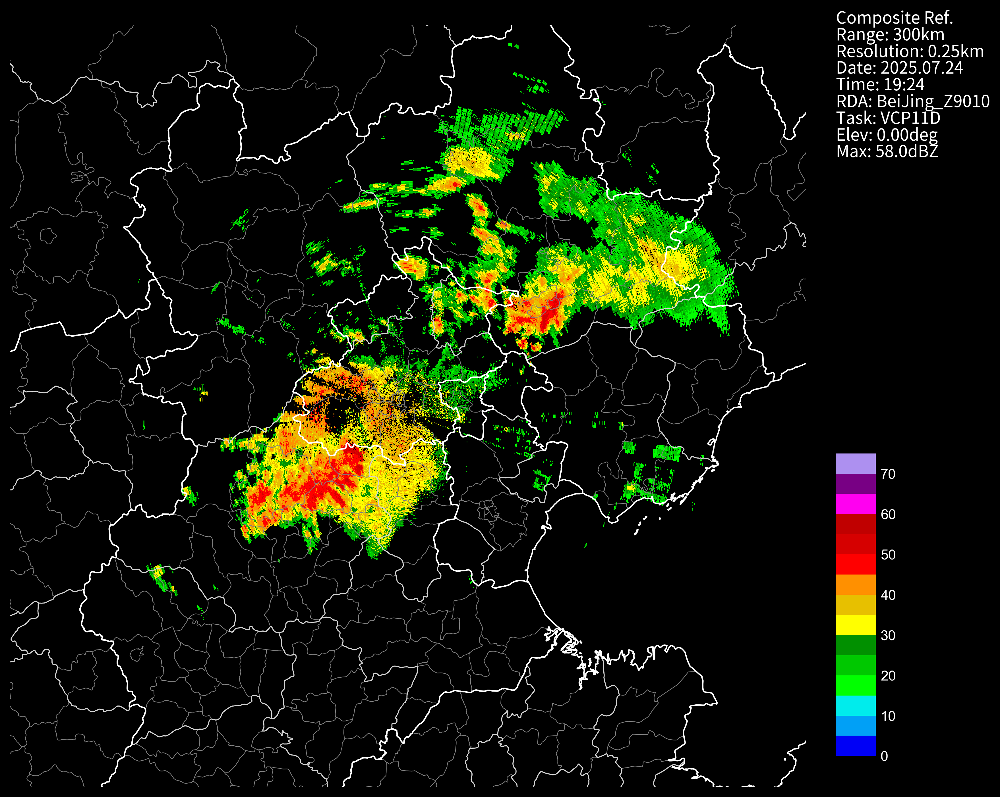

In [14]:
from cinrad.visualize import PPI

z9010_ppi_range_km = z9010_meb_range_km
_z9010_ref_tilts = list(z9010_cinrad_file.available_tilt('REF'))
_z9010_kdp_tilts = list(z9010_cinrad_file.available_tilt('KDP'))
z9010_plot_tilt = _z9010_ref_tilts[sweep_index]

z9010_refl_ds = z9010_cinrad_file.get_data(z9010_plot_tilt, z9010_ppi_range_km, 'REF')
z9010_kdp_ds = z9010_cinrad_file.get_data(_z9010_kdp_tilts[sweep_index], z9010_ppi_range_km, 'KDP')

ppi_refl = PPI(z9010_refl_ds)
ppi_kdp = PPI(z9010_kdp_ds)
ppi_cr = PPI(z9010_cr_ds_qc)

plt.show()


应用掩码过滤后数据图

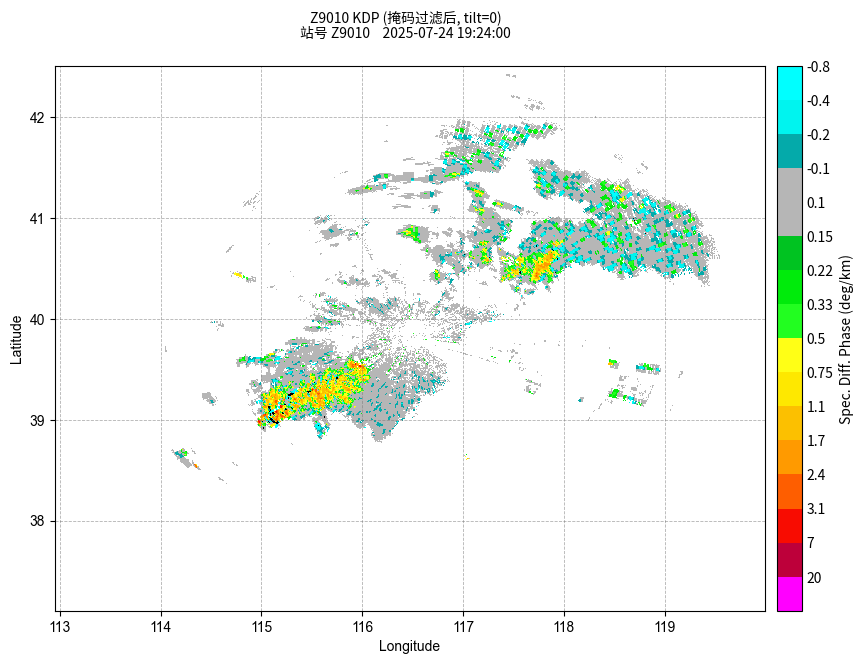

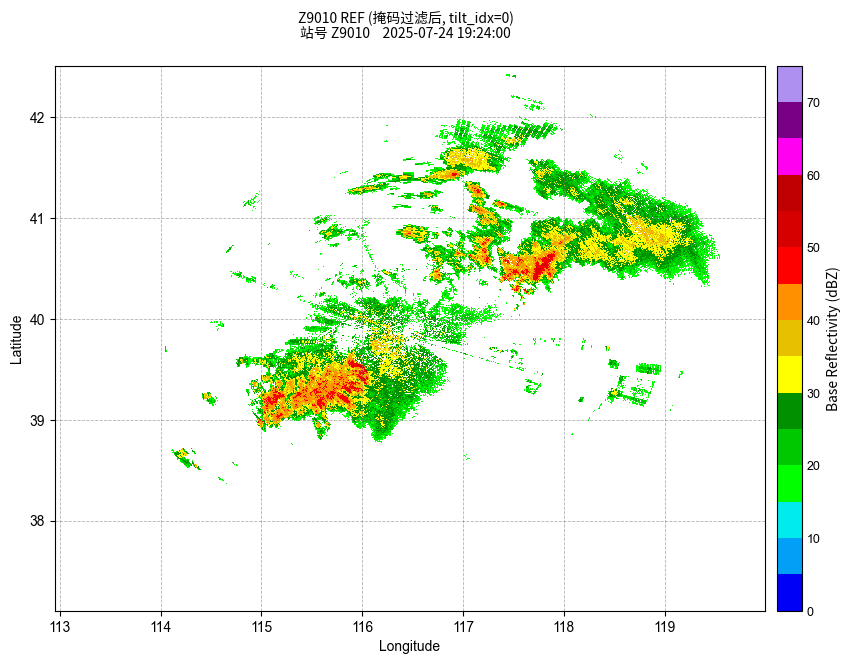

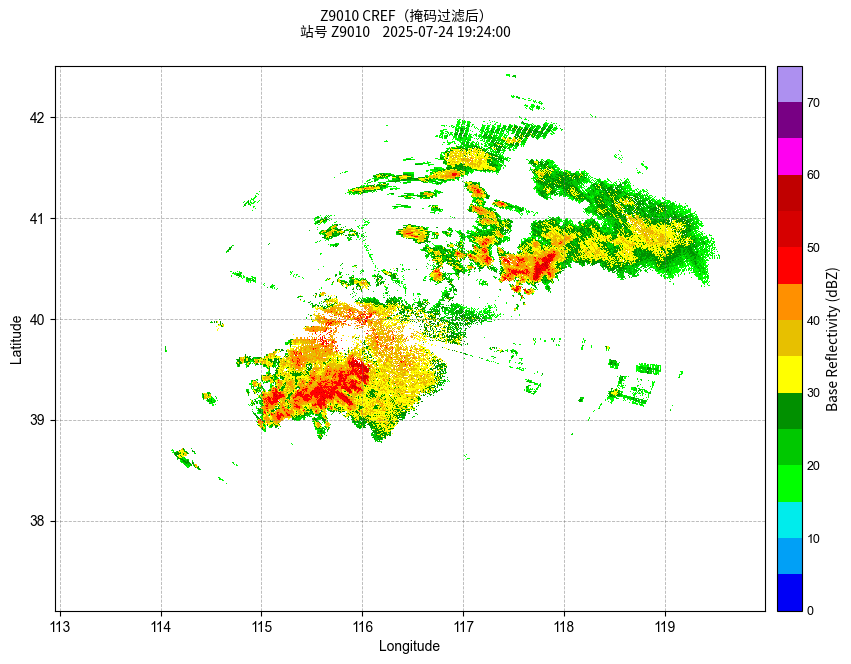

In [15]:
z9010_kdp_plot = plot_lonlat_field(
    kdp_data,
    target_lon,
    target_lat,
    'KDP',
    f'Z9010 KDP (掩码过滤后, tilt={sweep_index})\n{z9010_input_meta}',
    extent=z9010_compare_extent,
)
z9010_refl_plot = plot_lonlat_field(
    refl_data,
    cref_target_lon,
    cref_target_lat,
    'REF',
    f'Z9010 REF (掩码过滤后, tilt_idx={z9010_low_tilt_idx})\n{z9010_input_meta}',
    extent=z9010_compare_extent,
)
z9010_cref_plot = plot_lonlat_field(
    cref_data,
    cref_target_lon,
    cref_target_lat,
    'REF',
    f'Z9010 CREF（掩码过滤后）\n{z9010_input_meta}',
    extent=z9010_compare_extent,
)
for _fig in (z9010_kdp_plot.fig, z9010_refl_plot.fig, z9010_cref_plot.fig):
    display(_fig)
    plt.close(_fig)


### est_rain_rate_z

多仰角体扫：反射率输入为 `pyart.retrieve.composite_reflectivity` 得到的组合反射率。


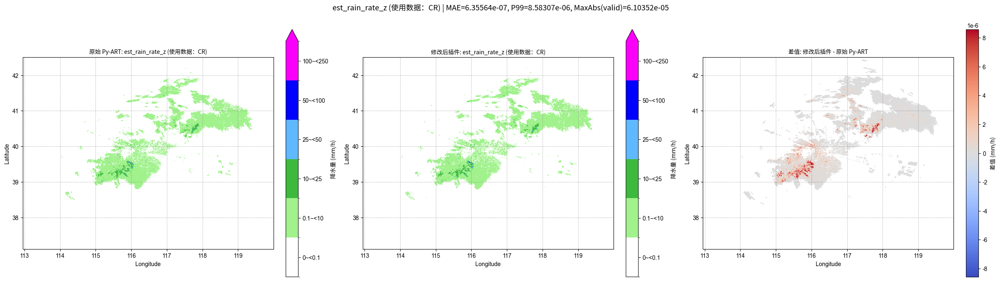

{'method': 'est_rain_rate_z (使用数据：CR)',
 'mae': 6.355642767630343e-07,
 'max_abs': 6.103515625e-05,
 'p99_abs': 8.58306884765625e-06,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [16]:
# 原算法
original_z_z9010 = pyart.retrieve.est_rain_rate_z(
    z9010_cref_radar,
    alpha=0.002,
    beta=0.8,
    refl_field='composite_reflectivity',
)['data']
original_z_z9010_data = extract_original_sweep_data(
    original_z_z9010,
    z9010_cref_sweep_slice,
    z9010_cref_sort_index,
)

# 插件算法
plugin_z_z9010 = EstimateRainRateZ(alpha=0.002, beta=0.8).process(refl=cref_griddata)
plugin_z_z9010_at_gates = sample_plugin_result_at_gates(
    plugin_z_z9010, cref_target_lat, cref_target_lon, z9010_cref_gate_lat, z9010_cref_gate_lon,
)

z_z9010_compare_record = plot_radar_lonlat_comparison(
    title=f'est_rain_rate_z (使用数据：CR)',
    original=original_z_z9010_data,
    migrated=plugin_z_z9010_at_gates,
    gate_lat=z9010_cref_gate_lat,
    gate_lon=z9010_cref_gate_lon,
    extent=z9010_compare_extent,
)
z_z9010_compare_record


### est_rain_rate_zpoly



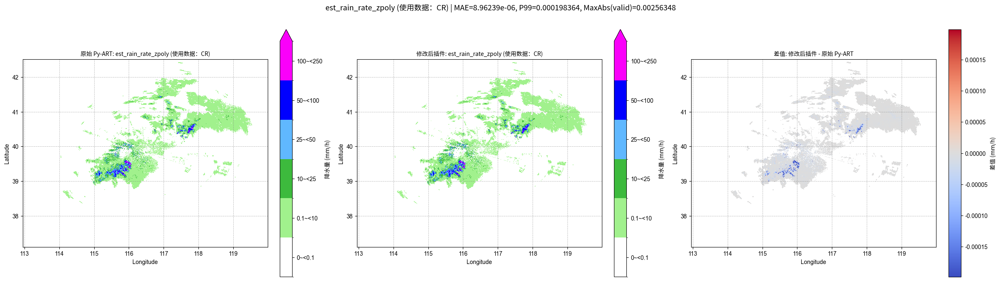

{'method': 'est_rain_rate_zpoly (使用数据：CR)',
 'mae': 8.962390893429983e-06,
 'max_abs': 0.0025634765625,
 'p99_abs': 0.0001983642578125,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [17]:
# 原算法
original_zpoly_z9010 = pyart.retrieve.est_rain_rate_zpoly(
    z9010_cref_radar,
    refl_field='composite_reflectivity',
)['data']
original_zpoly_z9010_data = extract_original_sweep_data(
    original_zpoly_z9010,
    z9010_cref_sweep_slice,
    z9010_cref_sort_index,
)

# 插件算法
plugin_zpoly_z9010 = EstimateRainRateZPoly().process(refl=cref_griddata)
plugin_zpoly_z9010_at_gates = sample_plugin_result_at_gates(
    plugin_zpoly_z9010, cref_target_lat, cref_target_lon, z9010_cref_gate_lat, z9010_cref_gate_lon,
)

zpoly_z9010_compare_record = plot_radar_lonlat_comparison(
    title=f'est_rain_rate_zpoly (使用数据：CR)',
    original=original_zpoly_z9010_data,
    migrated=plugin_zpoly_z9010_at_gates,
    gate_lat=z9010_cref_gate_lat,
    gate_lon=z9010_cref_gate_lon,
    extent=z9010_compare_extent,
)
zpoly_z9010_compare_record


### ZtoR

经典 `Z = aR^b` 关系；反射率输入为 **cinrad `quick_cr`**（与插件 `cref_griddata` 同源）。


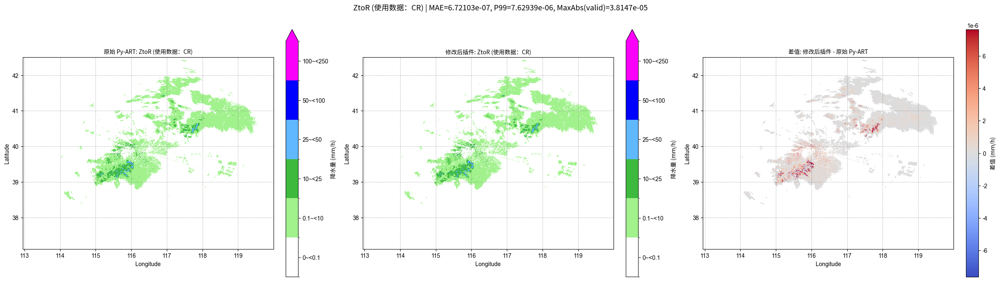

{'method': 'ZtoR (使用数据：CR)',
 'mae': 6.721029421896674e-07,
 'max_abs': 3.814697265625e-05,
 'p99_abs': 7.62939453125e-06,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [18]:
# 原算法
pyart.retrieve.ZtoR(
    z9010_cref_radar,
    a=280,
    b=1.75,
    ref_field='composite_reflectivity',
    save_name='NWS_primary_prate',
)
original_ztor_z9010_data = extract_pyart_retrieve_field(
    z9010_cref_radar,
    'NWS_primary_prate',
    z9010_cref_sweep_slice,
    z9010_cref_sort_index,
)

# 插件算法
plugin_ztor_z9010 = EstimateZtoR(a=280, b=1.75).process(refl=cref_griddata)
plugin_ztor_z9010_at_gates = sample_plugin_result_at_gates(
    plugin_ztor_z9010,
    cref_target_lat,
    cref_target_lon,
    z9010_cref_gate_lat,
    z9010_cref_gate_lon,
)

ztor_z9010_compare_record = plot_radar_lonlat_comparison(
    title=f'ZtoR (使用数据：CR)',
    original=original_ztor_z9010_data,
    migrated=plugin_ztor_z9010_at_gates,
    gate_lat=z9010_cref_gate_lat,
    gate_lon=z9010_cref_gate_lon,
    extent=z9010_compare_extent,
)
ztor_z9010_compare_record

### est_rain_rate_kdp

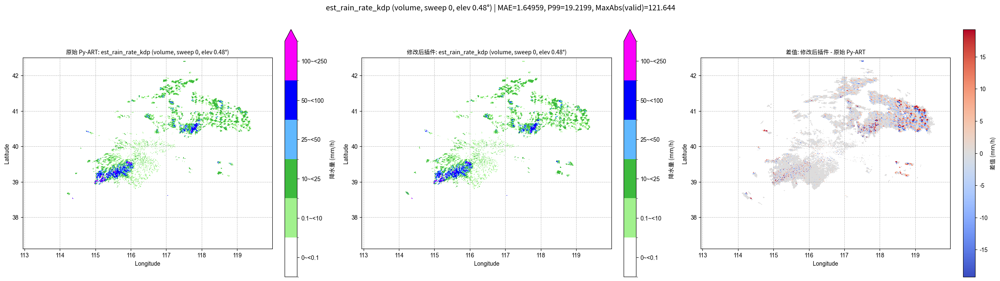

{'method': 'est_rain_rate_kdp (volume, sweep 0, elev 0.48°)',
 'mae': 1.6495938301086426,
 'max_abs': 121.64444732666016,
 'p99_abs': 19.219940185546875,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [19]:
# 原算法
original_kdp_rr = pyart.retrieve.est_rain_rate_kdp(
    z9010_radar, alpha=50.70, beta=0.8500, kdp_field=kdp_field,
)['data']
original_kdp_rr_data = extract_original_sweep_data(
    original_kdp_rr,
    sweep_slice,
    sort_index,
)

# 插件算法
plugin_kdp_volume = EstimateRainRateKdp(alpha=50.70, beta=0.8500).process(kdp=kdp_volume_grid)
#选取第一个仰角
plugin_kdp_rr = select_grid_level(plugin_kdp_volume, sweep_index)
plugin_kdp_rr_at_gates = sample_plugin_result_at_gates(
    plugin_kdp_rr, target_lat, target_lon, gate_lat, gate_lon,
)
#绘图
kdp_compare_record = plot_radar_lonlat_comparison(
    title=(
        f'est_rain_rate_kdp (volume, sweep {sweep_index}, '
        f'elev {z9010_elev_deg:.2f}°)'
    ),
    original=original_kdp_rr_data,
    migrated=plugin_kdp_rr_at_gates,
    gate_lat=gate_lat,
    gate_lon=gate_lon,
    extent=z9010_compare_extent,
)
kdp_compare_record


### est_rain_rate_zkdp

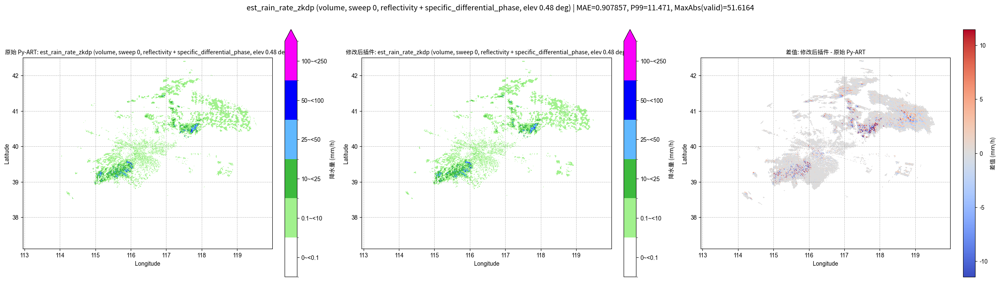

{'method': 'est_rain_rate_zkdp (volume, sweep 0, reflectivity + specific_differential_phase, elev 0.48 deg)',
 'mae': 0.9078566431999207,
 'max_abs': 51.61640167236328,
 'p99_abs': 11.471006393432617,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [20]:
# 原算法
original_zkdp = pyart.retrieve.est_rain_rate_zkdp(
    z9010_radar,
    alphaz=0.0376, betaz=0.6112, alphakdp=50.70, betakdp=0.8500,
    refl_field=refl_field, kdp_field=kdp_field, main_field=kdp_field,
    thresh=2.5, thresh_max=True,
)['data']
original_zkdp_data = extract_original_sweep_data(
    original_zkdp,
    sweep_slice,
    sort_index,
)

# 插件算法
plugin_zkdp_volume = EstimateRainRateZKdp(
    alphaz=0.0376,
    betaz=0.6112,
    alphakdp=50.70,
    betakdp=0.8500,
    main_field=kdp_field,
    thresh=2.5,
    thresh_max=True,
).process(refl=refl_volume_grid, kdp=kdp_volume_grid)
#选取第一个仰角
plugin_zkdp = select_grid_level(plugin_zkdp_volume, sweep_index)
#绘图
plugin_zkdp_at_gates = sample_plugin_result_at_gates(
    plugin_zkdp, target_lat, target_lon,
    gate_lat, gate_lon,
)
zkdp_compare_record = plot_radar_lonlat_comparison(
    title=(
        f'est_rain_rate_zkdp (volume, sweep {sweep_index}, '
        f'{refl_field} + {kdp_field}, '
        f'elev {z9010_elev_deg:.2f} deg)'
    ),
    original=original_zkdp_data,
    migrated=plugin_zkdp_at_gates,
    gate_lat=gate_lat,
    gate_lon=gate_lon,
    extent=z9010_compare_extent,
)
zkdp_compare_record


## hydro雷达数据

该部分数据与 `echo_class.ipynb` 中的 `hydro_radar_echo_classification.nc` 相关

输入数据包括：
- `corrected_reflectivity`（所有反射率相关算法）
- `specific_differential_phase`（KDP）
- `specific_attenuation`
- `radar_echo_classification`

验证算法包括：
- `est_rain_rate_z`
- `est_rain_rate_zpoly`
- `est_rain_rate_kdp`
- `est_rain_rate_zkdp`
- `ZtoR`
- `est_rain_rate_a`
- `est_rain_rate_za`
- `est_rain_rate_hydro`


### 数据处理

In [21]:
# ===== hydro 章节专用处理函数（后续若模块化可迁出） =====

def haversine_distance(lat1, lon1, lat2, lon2, R=6371.0):
    """计算两点间大圆距离（公里）"""
    lat1_rad, lon1_rad = np.radians(lat1), np.radians(lon1)
    lat2_rad, lon2_rad = np.radians(lat2), np.radians(lon2)
    dlat = lat2_rad - lat1_rad
    dlon = lon2_rad - lon1_rad
    a = np.sin(dlat/2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
    return R * c

def apply_physical_limits(data, min_val=-50, max_val=100):
    """
    应用物理合理范围限制
    """
    data_clean = data.copy()
    data_clean[~np.isfinite(data_clean)] = np.nan
    data_clean[(data_clean < min_val) | (data_clean > max_val)] = np.nan
    return data_clean

def get_radar_field_units(radar, field_name):
    """
    从雷达数据获取字段的单位信息
    """
    if field_name in radar.fields:
        field_info = radar.fields[field_name]
        # 检查常见的关键字
        for key in ['units', 'unit', 'Units', 'Unit']:
            if key in field_info:
                return str(field_info[key])
    
    # 根据字段名推断单位
    field_units_map = {
        'reflectivity': 'dBZ',
        'corrected_reflectivity': 'dBZ',
        'specific_attenuation': 'dB/km',
        'specific_differential_phase': 'deg/km',
        'radar_echo_classification': 'category',
    }

    return field_units_map.get(field_name, '')


def get_radar_frequency(radar):
    """从雷达原数据读取工作频率 (Hz)，无法获取时返回 None。"""
    if not hasattr(radar, 'instrument_parameters'):
        return None
    params = radar.instrument_parameters
    if 'frequency' not in params:
        return None
    freq = np.asarray(params['frequency']['data']).squeeze()
    if freq.size == 0 or not np.isfinite(freq):
        return None
    return float(freq)


def get_meteva_default_attrs(radar, field_name, time, dtime=0, level=0, data_name="RADAR"):
    """
    获取meteva_base所需的默认属性
    """
    # 1. 获取单位
    units = get_radar_field_units(radar, field_name)
    
    # 2. 构建model名称
    radar_name = getattr(radar, 'instrument_name', 'RADAR')
    if hasattr(radar, 'site_name'):
        radar_name = radar.site_name
    elif hasattr(radar, 'instrument_name'):
        radar_name = radar.instrument_name
    
    model = f"{radar_name}_{field_name}"
    
    # 3. 其他默认属性
    attrs = {
        'units': units,                       # 数据单位
        'model': model,                       # 模式/要素信息
        'dtime_units': 'hour',                # 预报时效单位，默认为hour
        'level_type': 'altitude',             # 地形类型，雷达数据通常是高度
        'time_type': 'UT',                    # 时区类型，默认为UT
        'time_bounds': '[0,0]',               # 要素起止时间，默认为'[0,0]'
        'data_name': data_name,               # 数据名称
        'var_name': field_name,               # 变量名称
        'sweep': 0,                           # 仰角编号
        'radar_lat': float(radar.latitude['data'][0]) if hasattr(radar, 'latitude') else 0.0,
        'radar_lon': float(radar.longitude['data'][0]) if hasattr(radar, 'longitude') else 0.0,
        'radar_alt': float(radar.altitude['data'][0]) if hasattr(radar, 'altitude') else 0.0,
    }
    
    freq = get_radar_frequency(radar)
    if freq is not None:
        attrs['frequency'] = freq

    return attrs


def remap_gate_data_with_flexible_range(
    values, gate_lon, gate_lat, target_lon, target_lat,
    method="nearest", range_strategy="auto_90", max_range_km=None,
    radar_lat=None, radar_lon=None, verbose=False, apply_limits=True,
):
    """
    优化版雷达数据网格化函数
    """
    # 1. 展平输入数据
    values_flat = values.ravel()
    gate_lon_flat = gate_lon.ravel()
    gate_lat_flat = gate_lat.ravel()
    
    # 2. 过滤无效值
    valid_mask = np.isfinite(values_flat)
    
    if not np.any(valid_mask):
        if verbose:
            print("警告: 没有有效数据")
        return {
            "data": np.full((len(target_lat), len(target_lon)), np.nan, dtype=np.float32),
            "longitude": target_lon,
            "latitude": target_lat,
            "metadata": {"max_range_km": 0.0},
        }
    
    values_valid = values_flat[valid_mask]
    gate_lon_valid = gate_lon_flat[valid_mask]
    gate_lat_valid = gate_lat_flat[valid_mask]
    
    # 3. 计算最大范围（多种策略）
    if max_range_km is None and radar_lat is not None and radar_lon is not None:
        distances = haversine_distance(
            gate_lat_valid, gate_lon_valid,
            radar_lat, radar_lon
        )
        
        if len(distances) > 0:
            if range_strategy == "auto_90":
                max_range_km = np.percentile(distances, 90)
            elif range_strategy == "auto_95":
                max_range_km = np.percentile(distances, 95)
            elif range_strategy == "max":
                max_range_km = np.max(distances)
            else:  # 包括 "fixed" 和其他未定义策略
                max_range_km = 150.0
        else:
            max_range_km = 150.0
    elif max_range_km is None:
        max_range_km = 150.0
    
    if verbose:
        print(f"使用范围: {max_range_km:.1f} km (策略: {range_strategy})")
    
    # 4. 生成目标网格
    lon_grid, lat_grid = np.meshgrid(target_lon, target_lat)
    lon_grid_flat = lon_grid.ravel()
    lat_grid_flat = lat_grid.ravel()
    
    # 5. 几何掩膜（如果提供了雷达位置）
    mask_within_range = np.ones_like(lon_grid_flat, dtype=bool)
    if radar_lat is not None and radar_lon is not None and max_range_km is not None:
        dist_to_radar = haversine_distance(
            lat_grid_flat, lon_grid_flat,
            radar_lat, radar_lon
        )
        mask_within_range = dist_to_radar <= max_range_km
        
        if verbose:
            mask_ratio = np.sum(mask_within_range) / len(mask_within_range)
            print(f"几何掩膜: {mask_ratio*100:.1f}% 网格点在有效范围内")
    
    # 6. 初始化结果数组
    grid_values = np.full_like(lon_grid_flat, np.nan, dtype=np.float64)
    
    if np.any(mask_within_range) and len(values_valid) > 0:
        # 提取掩膜内的点
        lon_masked = lon_grid_flat[mask_within_range]
        lat_masked = lat_grid_flat[mask_within_range]
        
        try:
            # 执行插值
            grid_interp = griddata(
                (gate_lon_valid, gate_lat_valid),
                values_valid,
                (lon_masked, lat_masked),
                method=method,
                fill_value=np.nan
            )
            
            # 确保没有异常值
            grid_interp = np.where(np.isfinite(grid_interp), grid_interp, np.nan)
            
            # 放回结果
            grid_values[mask_within_range] = grid_interp
            
            if verbose:
                valid_interp = np.sum(np.isfinite(grid_interp))
                print(f"成功插值: {valid_interp} 个网格点")
                
        except Exception as e:
            if verbose:
                print(f"插值错误: {e}")
            # 保持为 NaN
    
    # 7. 重塑为二维
    if verbose:
        valid_before = np.sum(np.isfinite(grid_values))
        print(f"Before reshape: {valid_before} valid points, grid shape {lon_grid.shape}")
    grid_values_2d = grid_values.reshape(lon_grid.shape)
    if verbose:
        valid_after = np.sum(np.isfinite(grid_values_2d))
        print(f"After reshape: {valid_after} valid points")
    
    # 8. 连续量才做物理范围裁剪；分类场保持整数类别
    if apply_limits:
        grid_values_2d = apply_physical_limits(grid_values_2d)
    
    valid_data = grid_values_2d[np.isfinite(grid_values_2d)]
    metadata = {"max_range_km": float(max_range_km)}

    if verbose and valid_data.size > 0:
        valid_ratio = valid_data.size / grid_values_2d.size if grid_values_2d.size > 0 else 0.0
        print(
            f"有效数据范围: [{float(np.min(valid_data)):.2f}, {float(np.max(valid_data)):.2f}], "
            f"比例: {valid_ratio * 100:.1f}%"
        )
    
    return {
        "data": grid_values_2d.astype(np.float32),
        "longitude": target_lon,
        "latitude": target_lat,
        "metadata": metadata
    }

def convert_to_meteva_grid(grid_result, radar, field_name, time, dtime=0, level=0, 
                          data_name="RADAR", verbose=False):
    """
    将网格化结果转换为 meteva_base grid_data，并写入雷达站与频率等属性。
    """
    # 1. 提取经纬度数组
    lon_array = grid_result["longitude"]
    lat_array = grid_result["latitude"]
    
    # 2. 计算网格分辨率
    if len(lon_array) >= 2:
        dlon = float(lon_array[1] - lon_array[0])
    else:
        dlon = 0.01
    
    if len(lat_array) >= 2:
        dlat = float(lat_array[1] - lat_array[0])
    else:
        dlat = 0.01
    
    # 3. 处理时间
    if isinstance(time, str):
        time = pd.to_datetime(time)
    
    # 4. 获取meteva所需的默认属性
    meteva_attrs = get_meteva_default_attrs(radar, field_name, time, dtime, level, data_name)
    
    if verbose:
        print("meteva属性设置:")
        for key, value in meteva_attrs.items():
            if key in ['units', 'model', 'dtime_units', 'level_type', 'time_type', 'time_bounds']:
                print(f"  {key}: {value}")
    
    # 5. 创建meteva网格对象
    try:
        # 尝试使用gtime参数
        grid = meb.grid(
            [float(lon_array.min()), float(lon_array.max()), dlon],
            [float(lat_array.min()), float(lat_array.max()), dlat],
            gtime=time,
            dtime_list=[dtime],
            level_list=[level],
            member_list=[data_name],
        )
    except TypeError:
        # 回退方案
        grid = meb.grid(
            [float(lon_array.min()), float(lon_array.max()), dlon],
            [float(lat_array.min()), float(lat_array.max()), dlat],
        )
    
    # 6. 创建网格数据
    gdata = meb.grid_data(
        grid,
        np.asarray(grid_result["data"], dtype=np.float32)
    )
    
    # 7. 设置变量名
    gdata.name = field_name
    
    # 8. 设置所有必需的属性
    for key, value in meteva_attrs.items():
        if hasattr(gdata, 'attrs'):
            gdata.attrs[key] = value
        elif hasattr(gdata, '_attributes'):
            gdata._attributes[key] = value
    
    return gdata


def build_target_latlon_axes_from_gate_coords(
    gate_lon,
    gate_lat,
    resolution=0.01,
    pad_ratio=0.02,
    min_pad_deg=0.05,
):
    """根据门点经纬度的最小/最大值构建规则网格坐标轴。"""
    gate_lon_flat = np.asarray(gate_lon, dtype=np.float64).ravel()
    gate_lat_flat = np.asarray(gate_lat, dtype=np.float64).ravel()
    valid = np.isfinite(gate_lon_flat) & np.isfinite(gate_lat_flat)
    if not np.any(valid):
        raise ValueError("门点经纬度中没有有效坐标，无法确定目标网格范围")

    lon_min = float(np.min(gate_lon_flat[valid]))
    lon_max = float(np.max(gate_lon_flat[valid]))
    lat_min = float(np.min(gate_lat_flat[valid]))
    lat_max = float(np.max(gate_lat_flat[valid]))

    lon_pad = max((lon_max - lon_min) * pad_ratio, min_pad_deg)
    lat_pad = max((lat_max - lat_min) * pad_ratio, min_pad_deg)
    lon_min -= lon_pad
    lon_max += lon_pad
    lat_min -= lat_pad
    lat_max += lat_pad

    target_lon = np.arange(lon_min, lon_max + resolution * 0.5, resolution)
    target_lat = np.arange(lat_min, lat_max + resolution * 0.5, resolution)
    if target_lon.size < 2:
        target_lon = np.array([lon_min, lon_max], dtype=np.float64)
    if target_lat.size < 2:
        target_lat = np.array([lat_min, lat_max], dtype=np.float64)
    return target_lon, target_lat


def process_and_save_radar_data(
    radar, field, sweep=0, resolution=0.01,
    time=None, dtime=0, level=0,
    data_name="RADAR", var_name=None,
    range_strategy="auto_90", method="nearest",
    target_lon=None, target_lat=None,
    output_dir="./output", filename_template=None, output_path=None,
    verbose=False, save_meteva_nc=True, apply_limits=True,
):
    """处理单个雷达字段，转换为 meteva 网格，并保存为 NetCDF。"""
    if var_name is None:
        var_name = field

    radar_lat = radar.latitude["data"][0]
    radar_lon = radar.longitude["data"][0]

    if time is None:
        time_units = radar.time["units"]
        if "since" in time_units:
            base_time_str = time_units.split("since ")[1]
            base_time = pd.to_datetime(base_time_str.replace("Z", ""))
            time = base_time + pd.Timedelta(seconds=float(radar.time["data"][0]))
        else:
            time = datetime.now()

    gate_lon, gate_lat = calculate_gate_coordinates(radar, sweep)
    if target_lon is None or target_lat is None:
        target_lon, target_lat = build_target_latlon_axes_from_gate_coords(
            gate_lon,
            gate_lat,
            resolution=resolution,
        )

    if verbose:
        gate_lon_valid = np.asarray(gate_lon, dtype=np.float64).ravel()
        gate_lat_valid = np.asarray(gate_lat, dtype=np.float64).ravel()
        gate_valid = np.isfinite(gate_lon_valid) & np.isfinite(gate_lat_valid)
        print(f"处理字段: {field}")
        print(f"雷达位置: ({radar_lat:.3f}, {radar_lon:.3f})")
        print(f"扫描时间: {time}")
        print(
            f"门点范围: 经度[{np.min(gate_lon_valid[gate_valid]):.3f}~{np.max(gate_lon_valid[gate_valid]):.3f}], "
            f"纬度[{np.min(gate_lat_valid[gate_valid]):.3f}~{np.max(gate_lat_valid[gate_valid]):.3f}]"
        )
        print(f"目标网格: 经度[{target_lon[0]:.3f}~{target_lon[-1]:.3f}], 纬度[{target_lat[0]:.3f}~{target_lat[-1]:.3f}]")

    data = radar.get_field(sweep, field)

    grid_result = remap_gate_data_with_flexible_range(
        values=data,
        gate_lon=gate_lon,
        gate_lat=gate_lat,
        target_lon=target_lon,
        target_lat=target_lat,
        method=method,
        range_strategy=range_strategy,
        max_range_km=None,
        radar_lat=radar_lat,
        radar_lon=radar_lon,
        verbose=verbose,
        apply_limits=apply_limits,
    )

    meteva_grid = convert_to_meteva_grid(
        grid_result=grid_result,
        radar=radar,
        field_name=field,
        time=time,
        dtime=dtime,
        level=level,
        data_name=data_name,
        verbose=verbose,
    )

    saved_path = None
    if save_meteva_nc:
        if output_path is None:
            if filename_template is None:
                time_str = time.strftime("%Y%m%d%H%M") if hasattr(time, "strftime") else str(time)
                filename = f"{field}_sweep{sweep}_{time_str}_{range_strategy}.nc"
            else:
                time_str = time.strftime("%Y%m%d%H%M") if hasattr(time, "strftime") else str(time)
                filename = filename_template.format(
                    field=field,
                    sweep=sweep,
                    time=time_str,
                    range_strategy=range_strategy,
                    method=method,
                )
            if not filename.endswith(".nc"):
                filename += ".nc"
            save_target = os.path.join(output_dir, filename)
        else:
            save_target = str(output_path)

        try:
            saved_path = save_meteva_grid_to_netcdf(meteva_grid, output_path=str(save_target), show=False)
            if verbose:
                print(f"已保存: {saved_path}")
        except (OSError, PermissionError) as e:
            if verbose:
                print(f"保存失败: field={field}, path={save_target}, error={e}")
            saved_path = None

    return meteva_grid, grid_result, saved_path


CATEGORICAL_RADAR_FIELDS = frozenset({"radar_echo_classification"})


def get_default_field_process_options(field_name, method="nearest", apply_limits=True):
    """返回字段级默认处理参数（分类场不做物理裁剪）。"""
    if field_name in CATEGORICAL_RADAR_FIELDS:
        return {"method": "nearest", "apply_limits": False}
    return {"method": method, "apply_limits": apply_limits}


def unpack_process_result(result, field_name):
    """解包 process/batch 的单字段返回值。"""
    if isinstance(result, dict) and "error" in result:
        raise RuntimeError(f"处理字段 {field_name} 失败: {result['error']}")
    meteva_grid, grid_result, saved_path = result
    meteva_grid.name = field_name
    return meteva_grid, grid_result, Path(saved_path) if saved_path else None


def build_latlon_plot_arrays(meteva_grid, grid_result):
    """从网格化结果构建 PPI 绘图所需的二维场和经纬度网格。"""
    target_lon = np.asarray(grid_result["longitude"], dtype=np.float64)
    target_lat = np.asarray(grid_result["latitude"], dtype=np.float64)
    lon_2d, lat_2d = np.meshgrid(target_lon, target_lat)
    data_2d = masked_to_nan(meteva_grid.values).squeeze()
    return data_2d, lon_2d, lat_2d, target_lon, target_lat


def compute_map_extent(lon_2d, lat_2d, *data_arrays, pad_ratio=0.06, min_pad_deg=0.05):
    """根据规则经纬度网格上的有效数据计算绘图 extent。"""
    lon_mins, lon_maxs, lat_mins, lat_maxs = [], [], [], []

    def _add_extent(lon, lat, data):
        lon = np.asarray(lon)
        lat = np.asarray(lat)
        data = np.asarray(data)
        mask = np.isfinite(data)
        if mask.shape != lon.shape or mask.shape != lat.shape:
            raise ValueError(
                f"extent shape mismatch: data {mask.shape}, lon {lon.shape}, lat {lat.shape}"
            )
        if not np.any(mask):
            return
        valid_lon = lon[mask]
        valid_lat = lat[mask]
        lon_mins.append(float(np.nanmin(valid_lon)))
        lon_maxs.append(float(np.nanmax(valid_lon)))
        lat_mins.append(float(np.nanmin(valid_lat)))
        lat_maxs.append(float(np.nanmax(valid_lat)))

    def _flush_masks(group_lon, group_lat, masks):
        if not masks:
            return
        merged = masks[0]
        for mask in masks[1:]:
            merged = merged | mask
        _add_extent(group_lon, group_lat, np.where(merged, 0.0, np.nan))

    shared_lon = np.asarray(lon_2d)
    shared_lat = np.asarray(lat_2d)
    group_lon, group_lat = shared_lon, shared_lat
    pending_masks = []

    for item in data_arrays:
        if isinstance(item, tuple) and len(item) == 3:
            _flush_masks(group_lon, group_lat, pending_masks)
            pending_masks = []
            _add_extent(*item)
            group_lon, group_lat = shared_lon, shared_lat
            continue

        mask = np.isfinite(np.asarray(item))
        if not pending_masks:
            pending_masks.append(mask)
        elif pending_masks[0].shape == mask.shape:
            pending_masks.append(mask)
        else:
            _flush_masks(group_lon, group_lat, pending_masks)
            if mask.shape != shared_lon.shape:
                raise ValueError(
                    f"data shape {mask.shape} differs from lon/lat {shared_lon.shape}; "
                    "pass (lon_2d, lat_2d, data) for this field"
                )
            pending_masks = [mask]

    _flush_masks(group_lon, group_lat, pending_masks)

    if not lon_mins:
        return None
    lon_min, lon_max = min(lon_mins), max(lon_maxs)
    lat_min, lat_max = min(lat_mins), max(lat_maxs)
    lon_pad = max((lon_max - lon_min) * pad_ratio, min_pad_deg)
    lat_pad = max((lat_max - lat_min) * pad_ratio, min_pad_deg)
    return [lon_min - lon_pad, lon_max + lon_pad, lat_min - lat_pad, lat_max + lat_pad]


def batch_process_and_save_radar_fields(
    radar,
    fields=None,
    sweep=0,
    resolution=0.01,
    time=None,
    dtime=0,
    level=0,
    data_name="RADAR",
    range_strategy="auto_90",
    method="nearest",
    apply_limits=True,
    output_dir="./output",
    filename_templates=None,
    output_paths=None,
    field_options=None,
    verbose=False,
    save_meteva_nc=True,
    raise_on_error=False,
):
    """批量网格化雷达字段并保存为 meteva NetCDF。"""
    if fields is None:
        priority_fields = [
            "corrected_reflectivity",
            "reflectivity",
            "specific_attenuation",
            "specific_differential_phase",
            "radar_echo_classification",
            "velocity",
            "differential_reflectivity",
            "cross_correlation_ratio",
        ]
        fields = [name for name in priority_fields if name in radar.fields]
        if not fields:
            fields = list(radar.fields.keys())

    filename_templates = filename_templates or {}
    output_paths = output_paths or {}
    field_options = field_options or {}

    if verbose:
        print(f"批量处理 {len(fields)} 个字段 -> {output_dir}")

    results = {}
    for field in fields:
        per_field = {
            **get_default_field_process_options(field, method=method, apply_limits=apply_limits),
            **field_options.get(field, {}),
        }
        field_output_path = output_paths.get(field)
        field_output_dir = str(Path(field_output_path).parent) if field_output_path else output_dir
        try:
            results[field] = process_and_save_radar_data(
                radar=radar,
                field=field,
                sweep=sweep,
                resolution=resolution,
                time=time,
                dtime=dtime,
                level=level,
                data_name=data_name,
                range_strategy=per_field.get("range_strategy", range_strategy),
                method=per_field.get("method", method),
                apply_limits=per_field.get("apply_limits", apply_limits),
                output_dir=field_output_dir,
                filename_template=filename_templates.get(field),
                output_path=field_output_path,
                verbose=verbose,
                save_meteva_nc=save_meteva_nc,
            )
        except Exception as exc:
            if raise_on_error:
                raise
            results[field] = {"error": str(exc)}
            if verbose:
                print(f"字段 {field} 处理失败: {exc}")

    if verbose:
        ok = sum(1 for item in results.values() if not (isinstance(item, dict) and "error" in item))
        print(f"完成: {ok}/{len(fields)} 个字段成功")
    return results

In [22]:
hydro_file = TEST_DATA_DIR / 'hydro_radar_echo_classification.nc'
hydro_sweep_index = 0
# 与 ACHN/CLI 保持一致：hydro 预处理输出统一落到 CLI_INPUT_DIR
hydro_input_dir = CLI_INPUT_DIR

# 字段定义
hydro_refl_field = 'corrected_reflectivity'  # 反射率
hydro_kdp_field = 'specific_differential_phase'  # KDP
hydro_att_field = 'specific_attenuation'  # 比衰减
hydro_class_field = 'radar_echo_classification'  # 水凝物分类

# 预处理输出路径
hydro_refl_meb_file = hydro_input_dir / 'hydro_corrected_reflectivity.nc'
hydro_att_meb_file = hydro_input_dir / 'hydro_specific_attenuation.nc'
hydro_class_meb_file = hydro_input_dir / 'hydro_radar_echo_classification.nc'
hydro_kdp_meb_file = hydro_input_dir / 'hydro_kdp.nc'
hydro_range_strategy = 'max'
hydro_grid_resolution = 0.01
hydro_grid_method = 'nearest'

# 读取 hydro 雷达并做字段完整性校验
hydro_radar = pyart.io.read(str(hydro_file)) if hydro_file.exists() else None
if hydro_radar is None:
    raise FileNotFoundError(
        f'Derived hydro file not found: {hydro_file}. '
        'Run the hydro save block in echo_class.ipynb first.'
    )

required_hydro_fields = [hydro_refl_field, hydro_kdp_field, hydro_att_field, hydro_class_field]
missing_hydro_fields = [f for f in required_hydro_fields if f not in hydro_radar.fields]
if missing_hydro_fields:
    raise KeyError(f'Missing fields in derived hydro file: {missing_hydro_fields}')

hydro_process_fields = list(required_hydro_fields)

# 每个字段对应的落盘路径（供批处理函数直接写入）
hydro_output_paths = {
    hydro_refl_field: hydro_refl_meb_file,
    hydro_att_field: hydro_att_meb_file,
    hydro_class_field: hydro_class_meb_file,
    hydro_kdp_field: hydro_kdp_meb_file,
}

# 提取当前 sweep 的门点索引、排序索引和门点经纬度
hydro_ctx = get_radar_sweep_context(hydro_radar, hydro_sweep_index)
hydro_sweep_slice = hydro_ctx['sweep_slice']
hydro_sort_index = hydro_ctx['sort_index']
hydro_gate_lon = hydro_ctx['gate_lon']
hydro_gate_lat = hydro_ctx['gate_lat']

# 批量预处理四个 hydro 输入字段（网格化 + 落盘）
hydro_batch_results = batch_process_and_save_radar_fields(
    radar=hydro_radar,
    fields=hydro_process_fields,
    sweep=hydro_sweep_index,
    resolution=hydro_grid_resolution,
    range_strategy=hydro_range_strategy,
    method=hydro_grid_method,
    output_dir=str(hydro_input_dir),
    output_paths=hydro_output_paths,
)

# 解包批处理结果：得到每个字段的 grid_data 与中间 grid_result
hydro_refl_grid, hydro_refl_grid_result, hydro_refl_meb_file = unpack_process_result(
    hydro_batch_results[hydro_refl_field], hydro_refl_field,
)
hydro_att_grid, hydro_att_grid_result, hydro_att_meb_file = unpack_process_result(
    hydro_batch_results[hydro_att_field], hydro_att_field,
)
hydro_class_grid, hydro_class_grid_result, hydro_class_meb_file = unpack_process_result(
    hydro_batch_results[hydro_class_field], hydro_class_field,
)
hydro_kdp_grid, hydro_kdp_grid_result, hydro_kdp_meb_file = unpack_process_result(
    hydro_batch_results[hydro_kdp_field], hydro_kdp_field,
)

# 构建绘图/采样所需数组：二维场、二维经纬度、1D 目标经纬度
hydro_refl_2d, hydro_lon_2d, hydro_lat_2d, hydro_target_lon, hydro_target_lat = build_latlon_plot_arrays(
    hydro_refl_grid, hydro_refl_grid_result,
)
hydro_att_2d, _, _, _, _ = build_latlon_plot_arrays(hydro_att_grid, hydro_att_grid_result)
hydro_class_2d, _, _, _, _ = build_latlon_plot_arrays(hydro_class_grid, hydro_class_grid_result)
hydro_kdp_2d, _, _, _, _ = build_latlon_plot_arrays(hydro_kdp_grid, hydro_kdp_grid_result)

# 依据有效值范围生成统一地图 extent，供后续对比图复用
hydro_extent_inputs = [hydro_refl_2d, hydro_kdp_2d, hydro_att_2d, hydro_class_2d]
hydro_extent = compute_map_extent(
    hydro_lon_2d,
    hydro_lat_2d,
    *hydro_extent_inputs,
)


### 输入数据图



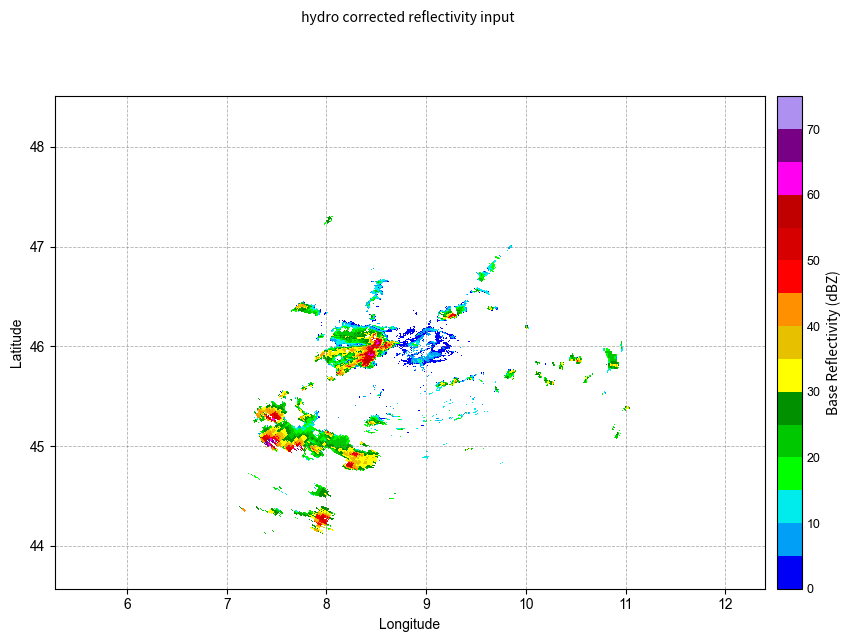

In [23]:
refl_plot = plot_lonlat_field(
    hydro_refl_2d.astype(np.float32),
    hydro_lon_2d,
    hydro_lat_2d,
    'REF',
    ' hydro corrected reflectivity input',
    extent=hydro_extent,
)
display(refl_plot.fig)
plt.close(refl_plot.fig)

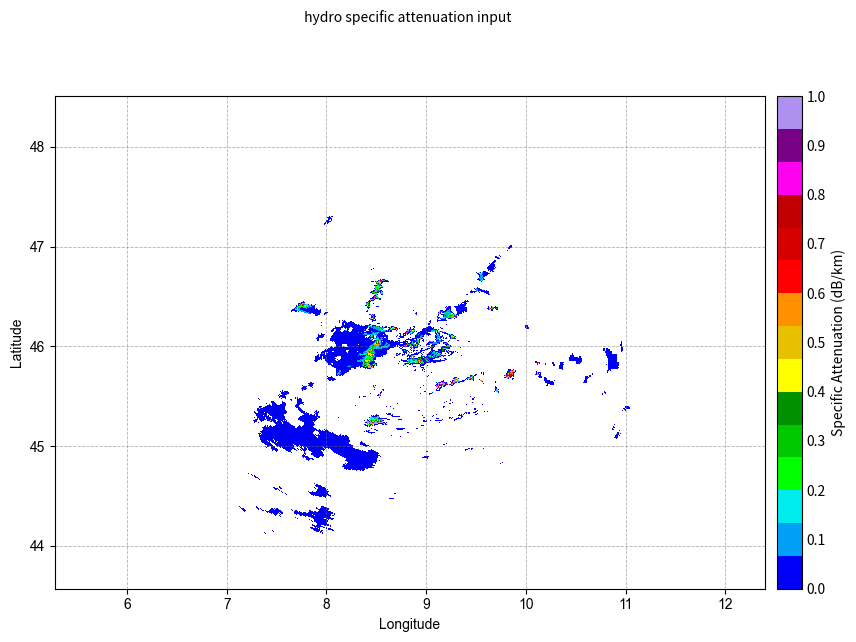

In [24]:
from cinrad.visualize.gpf import _cmap

cmap_Ah = _cmap('REF')['cmap']
norm_Ah = plt.Normalize(vmin=0.0, vmax=1.0)
att_ticks = np.arange(0.0, 1.01, 0.1)
at_plot = plot_lonlat_field(
    hydro_att_2d.astype(np.float32),
    hydro_lon_2d,
    hydro_lat_2d,
    'REF',
    ' hydro specific attenuation input',
    extent=hydro_extent,
    cmap=cmap_Ah,
    norm=norm_Ah,
    cbar_label='Specific Attenuation (dB/km)',
    cbar_tick_labels=[f'{tick:.1f}' for tick in att_ticks],
)
display(at_plot.fig)
plt.close(at_plot.fig)

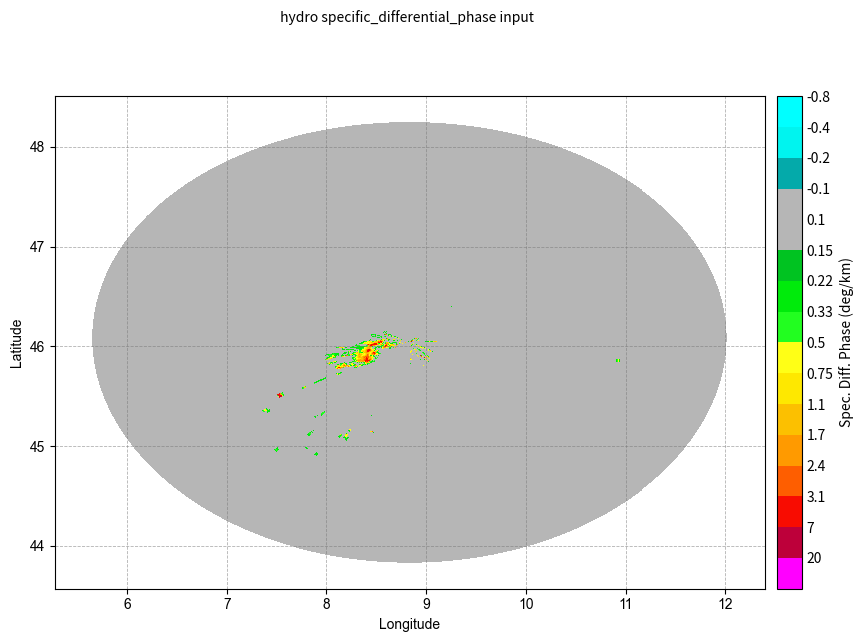

In [25]:
if hydro_kdp_grid is not None:
    kdp_plot = plot_lonlat_field(
        hydro_kdp_2d.astype(np.float32),
        hydro_lon_2d,
        hydro_lat_2d,
        'KDP',
        f' hydro {hydro_kdp_field} input',
        extent=hydro_extent,
    )
    display(kdp_plot.fig)
    plt.close(kdp_plot.fig)

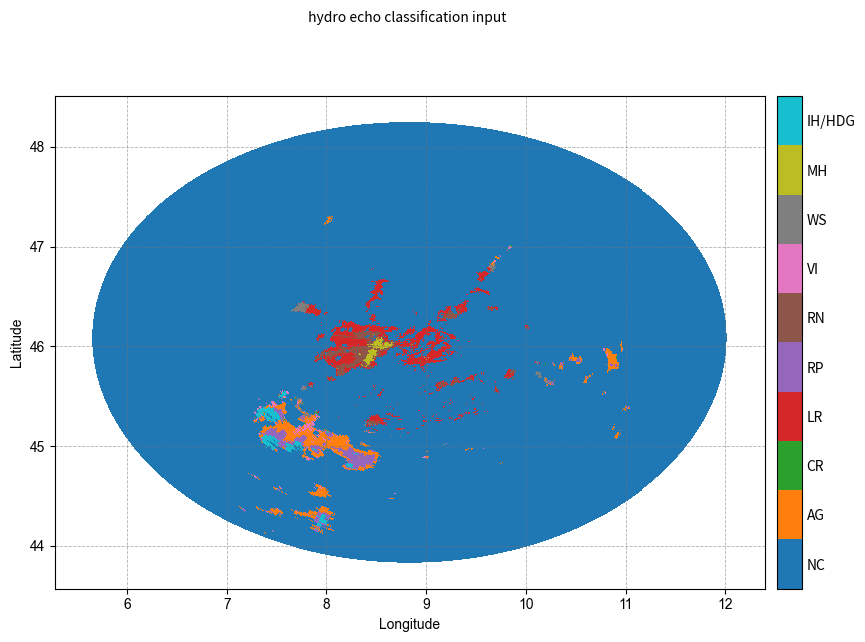

In [26]:
from matplotlib.colors import BoundaryNorm

hydro_labels = ['NC', 'AG', 'CR', 'LR', 'RP', 'RN', 'VI', 'WS', 'MH', 'IH/HDG']
hydro_ticks = np.arange(len(hydro_labels))
hydro_boundaries = np.arange(-0.5, len(hydro_labels), 1.0)
hydro_cmap = plt.get_cmap('tab10', len(hydro_labels))
hydro_norm = BoundaryNorm(hydro_boundaries, hydro_cmap.N)

class_plot = plot_lonlat_field(
    hydro_class_2d.astype(np.float32),
    hydro_lon_2d,
    hydro_lat_2d,
    'HCL',
    ' hydro echo classification input',
    extent=hydro_extent,
    cmap=hydro_cmap,
    norm=hydro_norm,
    cbar_tick_labels=hydro_labels,
)
display(class_plot.fig)
plt.close(class_plot.fig)

# NC = not classified
# AG = aggregates
# CR = ice crystals
# LR = light rain
# RP = rimed particles
# RN = rain
# VI = vertically oriented ice
# WS = wet snow
# MH = melting hail
# IH/HDG = dry hail / high density graupel

### est_rain_rate_z


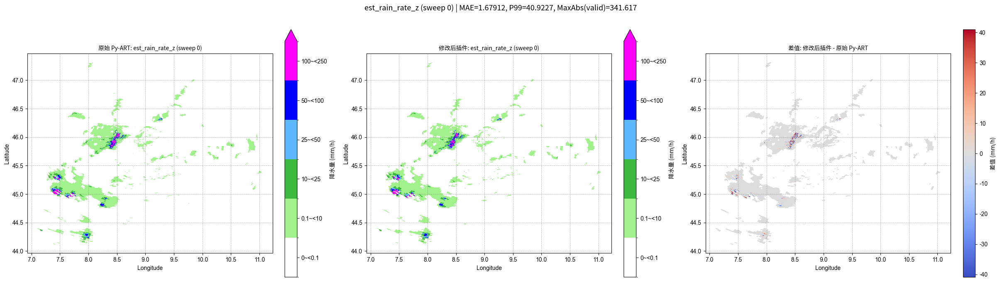

{'method': 'est_rain_rate_z (sweep 0)',
 'mae': 1.6791167259216309,
 'max_abs': 341.6165771484375,
 'p99_abs': 40.92268371582031,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [27]:
original_z = pyart.retrieve.est_rain_rate_z(
    hydro_radar,
    alpha=0.0376,
    beta=0.6112,
    refl_field=hydro_refl_field,
)['data']
original_z_data = extract_original_sweep_data(
    original_z,
    hydro_sweep_slice,
    hydro_sort_index,
)

plugin_z_hydro = EstimateRainRateZ(alpha=0.0376, beta=0.6112).process(refl=hydro_refl_grid)
plugin_z_hydro_at_gates = sample_plugin_result_at_gates(
    plugin_z_hydro,
    hydro_target_lat,
    hydro_target_lon,
    hydro_gate_lat,
    hydro_gate_lon,
)
z_hydro_compare_record = plot_radar_lonlat_comparison(
    title=f'est_rain_rate_z (sweep {hydro_sweep_index})',
    original=original_z_data,
    migrated=plugin_z_hydro_at_gates,
    gate_lat=hydro_gate_lat,
    gate_lon=hydro_gate_lon,
)
z_hydro_compare_record


### est_rain_rate_zpoly


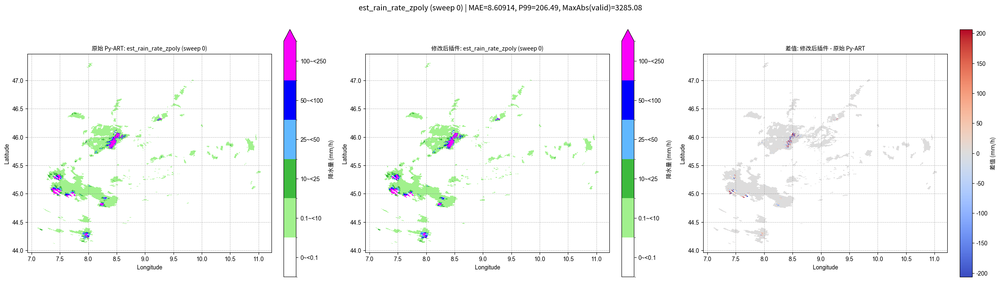

{'method': 'est_rain_rate_zpoly (sweep 0)',
 'mae': 8.60914134979248,
 'max_abs': 3285.080322265625,
 'p99_abs': 206.4897918701172,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [28]:
original_zpoly = pyart.retrieve.est_rain_rate_zpoly(
    hydro_radar,
    refl_field=hydro_refl_field,
)['data']
original_zpoly_data = extract_original_sweep_data(
    original_zpoly,
    hydro_sweep_slice,
    hydro_sort_index,
)

plugin_zpoly_hydro = EstimateRainRateZPoly().process(refl=hydro_refl_grid)
plugin_zpoly_hydro_at_gates = sample_plugin_result_at_gates(
    plugin_zpoly_hydro,
    hydro_target_lat,
    hydro_target_lon,
    hydro_gate_lat,
    hydro_gate_lon,
)
zpoly_hydro_compare_record = plot_radar_lonlat_comparison(
    title=f'est_rain_rate_zpoly (sweep {hydro_sweep_index})',
    original=original_zpoly_data,
    migrated=plugin_zpoly_hydro_at_gates,
    gate_lat=hydro_gate_lat,
    gate_lon=hydro_gate_lon,
)
zpoly_hydro_compare_record


### est_rain_rate_kdp

`est_rain_rate_kdp` 使用 KDP 场（见输入数据图）。


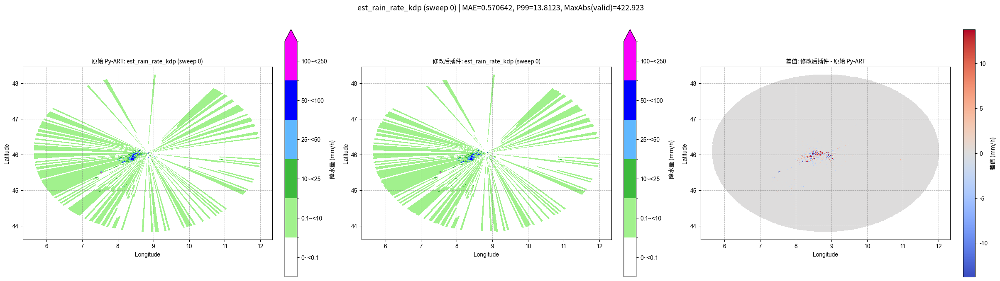

{'method': 'est_rain_rate_kdp (sweep 0)',
 'mae': 0.5706421136856079,
 'max_abs': 422.9231262207031,
 'p99_abs': 13.812261581420898,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [29]:
original_kdp_hydro = pyart.retrieve.est_rain_rate_kdp(
    hydro_radar,
    alpha=29.70,
    beta=0.8500,
    kdp_field=hydro_kdp_field,
)['data']
original_kdp_hydro_data = extract_original_sweep_data(
    original_kdp_hydro,
    hydro_sweep_slice,
    hydro_sort_index,
)

plugin_kdp_hydro = EstimateRainRateKdp(alpha=29.70, beta=0.8500).process(kdp=hydro_kdp_grid)
plugin_kdp_hydro_at_gates = sample_plugin_result_at_gates(
    plugin_kdp_hydro,
    hydro_target_lat,
    hydro_target_lon,
    hydro_gate_lat,
    hydro_gate_lon,
)
kdp_hydro_compare_record = plot_radar_lonlat_comparison(
    title=f'est_rain_rate_kdp (sweep {hydro_sweep_index})',
    original=original_kdp_hydro_data,
    migrated=plugin_kdp_hydro_at_gates,
    gate_lat=hydro_gate_lat,
    gate_lon=hydro_gate_lon,
)
kdp_hydro_compare_record


### est_rain_rate_zkdp


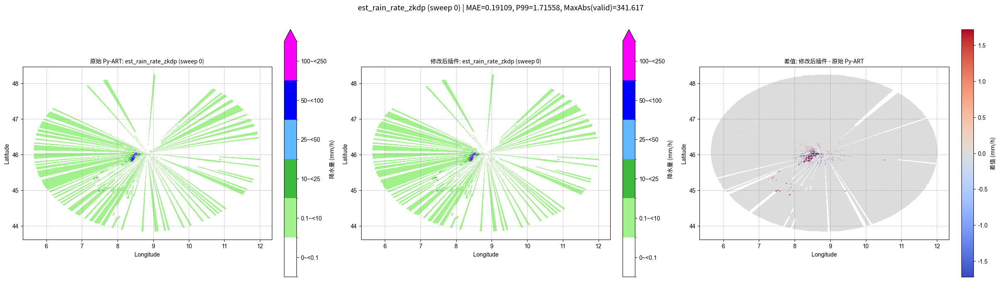

{'method': 'est_rain_rate_zkdp (sweep 0)',
 'mae': 0.19108989834785461,
 'max_abs': 341.6165771484375,
 'p99_abs': 1.7155848741531372,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [30]:
original_zkdp_hydro = pyart.retrieve.est_rain_rate_zkdp(
    hydro_radar,
    alphaz=0.0376,
    betaz=0.6112,
    alphakdp=29.70,
    betakdp=0.8500,
    refl_field=hydro_refl_field,
    kdp_field=hydro_kdp_field,
    main_field=hydro_kdp_field,
    thresh=2.5,
    thresh_max=True,
)['data']
original_zkdp_hydro_data = extract_original_sweep_data(
    original_zkdp_hydro,
    hydro_sweep_slice,
    hydro_sort_index,
)

plugin_zkdp_hydro = EstimateRainRateZKdp(
    alphaz=0.0376,
    betaz=0.6112,
    alphakdp=29.70,
    betakdp=0.8500,
    main_field=hydro_kdp_field,
    thresh=2.5,
    thresh_max=True,
).process(refl=hydro_refl_grid, kdp=hydro_kdp_grid)
plugin_zkdp_hydro_at_gates = sample_plugin_result_at_gates(
    plugin_zkdp_hydro,
    hydro_target_lat,
    hydro_target_lon,
    hydro_gate_lat,
    hydro_gate_lon,
)
zkdp_hydro_compare_record = plot_radar_lonlat_comparison(
    title=f'est_rain_rate_zkdp (sweep {hydro_sweep_index})',
    original=original_zkdp_hydro_data,
    migrated=plugin_zkdp_hydro_at_gates,
    gate_lat=hydro_gate_lat,
    gate_lon=hydro_gate_lon,
)
zkdp_hydro_compare_record


### ZtoR

`ZtoR` 使用 `corrected_reflectivity` 场，公式为 `Z = aR^b`。


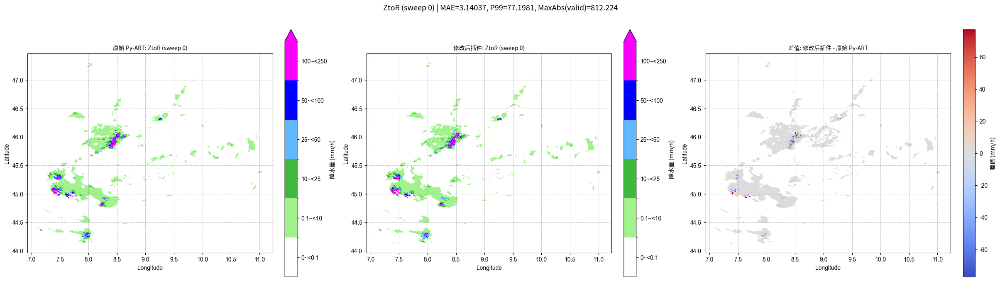

{'method': 'ZtoR (sweep 0)',
 'mae': 3.1403651237487793,
 'max_abs': 812.2244873046875,
 'p99_abs': 77.19805145263672,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [31]:
pyart.retrieve.ZtoR(
    hydro_radar,
    a=300.0,
    b=1.4,
    ref_field=hydro_refl_field,
    save_name="NWS_primary_prate",
)
original_ztor_hydro_data = extract_pyart_retrieve_field(
    hydro_radar,
    "NWS_primary_prate",
    hydro_sweep_slice,
    hydro_sort_index,
)

plugin_ztor_hydro = EstimateZtoR(a=300.0, b=1.4).process(refl=hydro_refl_grid)
plugin_ztor_hydro_at_gates = sample_plugin_result_at_gates(
    plugin_ztor_hydro,
    hydro_target_lat,
    hydro_target_lon,
    hydro_gate_lat,
    hydro_gate_lon,
)
ztor_hydro_compare_record = plot_radar_lonlat_comparison(
    title=f'ZtoR (sweep {hydro_sweep_index})',
    original=original_ztor_hydro_data,
    migrated=plugin_ztor_hydro_at_gates,
    gate_lat=hydro_gate_lat,
    gate_lon=hydro_gate_lon,
)
ztor_hydro_compare_record


### est_rain_rate_a 

`est_rain_rate_a` 使用 `specific_attenuation` 数据


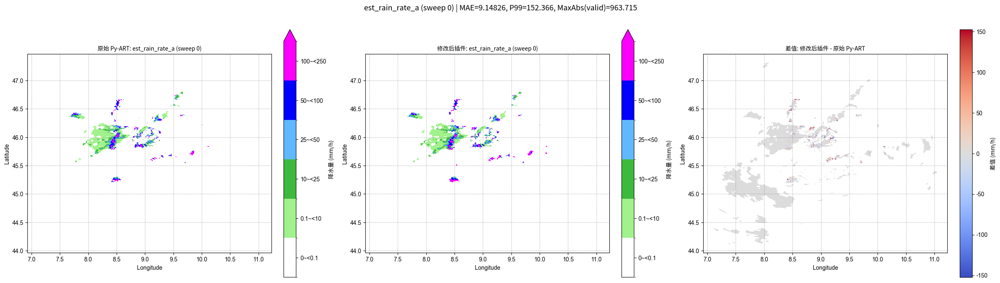

{'method': 'est_rain_rate_a (sweep 0)',
 'mae': 9.148258209228516,
 'max_abs': 963.71533203125,
 'p99_abs': 152.36618041992188,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [32]:
original_a = pyart.retrieve.est_rain_rate_a(
    hydro_radar, alpha=250.0, beta=0.91, a_field=hydro_att_field,
)['data']
original_a_data = extract_original_sweep_data(
    original_a,
    hydro_sweep_slice,
    hydro_sort_index,
)

# 插件算法
plugin_a = EstimateRainRateA(alpha=250.0, beta=0.91).process(att=hydro_att_grid)
plugin_a_at_gates = sample_plugin_result_at_gates(
    plugin_a,
    hydro_target_lat,
    hydro_target_lon,
    hydro_gate_lat,
    hydro_gate_lon,
)
a_compare_record = plot_radar_lonlat_comparison(
    title=f'est_rain_rate_a (sweep {hydro_sweep_index})',
    original=original_a_data,
    migrated=plugin_a_at_gates,
    gate_lat=hydro_gate_lat,
    gate_lon=hydro_gate_lon,
)
a_compare_record


### est_rain_rate_za


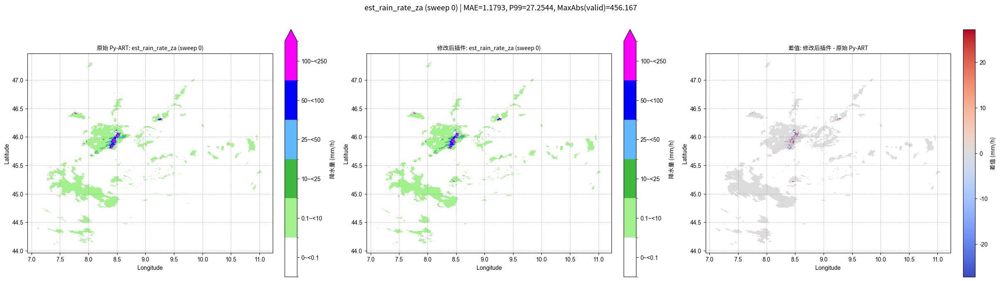

{'method': 'est_rain_rate_za (sweep 0)',
 'mae': 1.179295539855957,
 'max_abs': 456.1671142578125,
 'p99_abs': 27.254379272460938,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [33]:
original_za = pyart.retrieve.est_rain_rate_za(
    hydro_radar,
    alphaz=0.0376, betaz=0.6112, alphaa=250.0, betaa=0.91,
    main_field=hydro_refl_field, thresh=10.0, thresh_max=True,
    refl_field=hydro_refl_field, a_field=hydro_att_field,
)['data']
original_za_data = extract_original_sweep_data(
    original_za,
    hydro_sweep_slice,
    hydro_sort_index,
)

# 插件算法
plugin_za = EstimateRainRateZA(
    alphaz=0.0376,
    betaz=0.6112,
    alphaa=250.0,
    betaa=0.91,
    main_field=hydro_refl_field,
    thresh=10.0,
    thresh_max=True,
).process(refl=hydro_refl_grid, att=hydro_att_grid)
plugin_za_at_gates = sample_plugin_result_at_gates(
    plugin_za,
    hydro_target_lat,
    hydro_target_lon,
    hydro_gate_lat,
    hydro_gate_lon,
)
za_compare_record = plot_radar_lonlat_comparison(
    title=f'est_rain_rate_za (sweep {hydro_sweep_index})',
    original=original_za_data,
    migrated=plugin_za_at_gates,
    gate_lat=hydro_gate_lat,
    gate_lon=hydro_gate_lon,
)
za_compare_record


### est_rain_rate_hydro

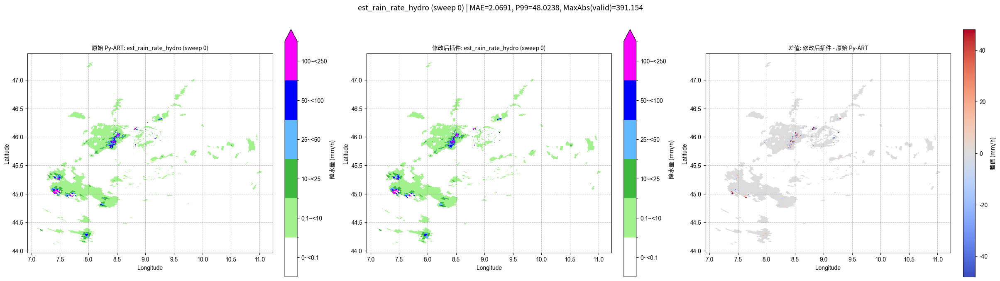

{'method': 'est_rain_rate_hydro (sweep 0)',
 'mae': 2.0691030025482178,
 'max_abs': 391.1536560058594,
 'p99_abs': 48.02381896972656,
 'vmin': np.float64(0.0),
 'vmax': np.float64(250.0)}

In [34]:
original_hydro = pyart.retrieve.est_rain_rate_hydro(
    hydro_radar,
    alphazr=0.0376, betazr=0.6112, alphazs=0.1, betazs=0.5, mp_factor=0.6,
    main_field=hydro_refl_field, thresh=0.04,
    refl_field=hydro_refl_field, a_field=hydro_att_field, hydro_field=hydro_class_field,
)['data']
original_hydro_data = extract_original_sweep_data(
    original_hydro,
    hydro_sweep_slice,
    hydro_sort_index,
)

# 插件算法
plugin_hydro = EstimateRainRateHydro(
    alphazr=0.0376,
    betazr=0.6112,
    alphazs=0.1,
    betazs=0.5,
    alphaa=250.0,
    betaa=0.91,
    mp_factor=0.6,
    main_field=hydro_refl_field,
    thresh=0.04,
).process(refl=hydro_refl_grid, att=hydro_att_grid, hydro=hydro_class_grid)
plugin_hydro_at_gates = sample_plugin_result_at_gates(
    plugin_hydro,
    hydro_target_lat,
    hydro_target_lon,
    hydro_gate_lat,
    hydro_gate_lon,
)
hydro_compare_record = plot_radar_lonlat_comparison(
    title=f'est_rain_rate_hydro (sweep {hydro_sweep_index})',
    original=original_hydro_data,
    migrated=plugin_hydro_at_gates,
    gate_lat=hydro_gate_lat,
    gate_lon=hydro_gate_lon,
)
hydro_compare_record


## CLI 应用示例

CLI 已改为 `radar_qpe_retrieval/cli/qpe.py` 中的 Python 函数入口。在 notebook 中直接 `from radar_qpe_retrieval.cli.qpe import process` 并调用；也可修改脚本底部 `if __name__ == '__main__'` 后运行：

```powershell
python radar_qpe_retrieval/cli/qpe.py
```


In [35]:
from radar_qpe_retrieval.cli.qpe import process

# 输入数据路径
achn_refl = CLI_INPUT_DIR / "ACHN_CREF000_20240612_070000.nc"
z9010_cref = CLI_INPUT_DIR / "Z9010_20250724192400_cref.nc"
# 输出路径
cli_z_file = CLI_OUTPUT_DIR / "est_rain_rate_z.nc"
cli_zpoly_file = CLI_OUTPUT_DIR / "est_rain_rate_zpoly.nc"
cli_ztor_file = CLI_OUTPUT_DIR / "est_rain_rate_ztor.nc"
cli_z9010_z_file = CLI_OUTPUT_DIR / "z9010_est_rain_rate_z.nc"

process("z", refl_path=str(achn_refl), z_alpha=0.0376, z_beta=0.6112, output_path=str(cli_z_file))

process("zpoly", refl_path=str(achn_refl), output_path=str(cli_zpoly_file))

process("ztor", refl_path=str(achn_refl), ztor_a=300.0, ztor_b=1.4, output_path=str(cli_ztor_file))

process("z", refl_path=str(z9010_cref), z_alpha=0.002, z_beta=0.8, output_path=str(cli_z9010_z_file))

<xarray.DataArray 'radar_estimated_rain_rate' (member: 1, level: 1, time: 1,
                                               dtime: 1, lat: 1000, lon: 1000)> Size: 4MB
array([[[[[[nan, nan, nan, ..., nan, nan, nan],
           [nan, nan, nan, ..., nan, nan, nan],
           [nan, nan, nan, ..., nan, nan, nan],
           ...,
           [nan, nan, nan, ..., nan, nan, nan],
           [nan, nan, nan, ..., nan, nan, nan],
           [nan, nan, nan, ..., nan, nan, nan]]]]]],
      shape=(1, 1, 1, 1, 1000, 1000), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[us] 8B 2025-07-24T19:24:00
  * dtime    (dtime) int32 4B 0
  * lat      (lat) float64 8kB 37.11 37.11 37.12 37.12 ... 42.5 42.5 42.51 42.51
  * lon      (lon) float64 8kB 113.0 113.0 113.0 113.0 ... 120.0 120.0 120.0
Attributes:
    units:        mm/h
    model_var:    
    dtime_units:  hour
    level_type:   isobaric
    time_type:    UT
    time_bounds:  [np.int64(0), np.int64(0)]
    long_name:    rain rate estimated from reflectivity

### CLI 结果对比

- **ACHN**：CLI 输出与上文 ACHN 网格原算法结果对比（`z` / `zpoly` / `ztor`，`plot_latlon_comparison`）
- **Z9010**：CLI 输出与 Z9010 小节 Py-ART `est_rain_rate_z` 门点结果对比（`plot_radar_lonlat_comparison`）


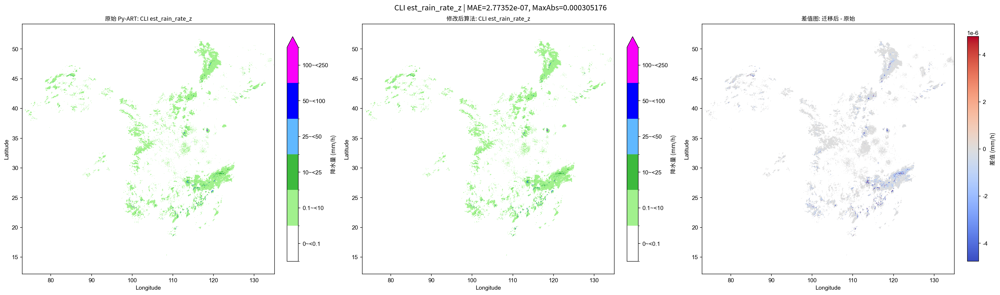

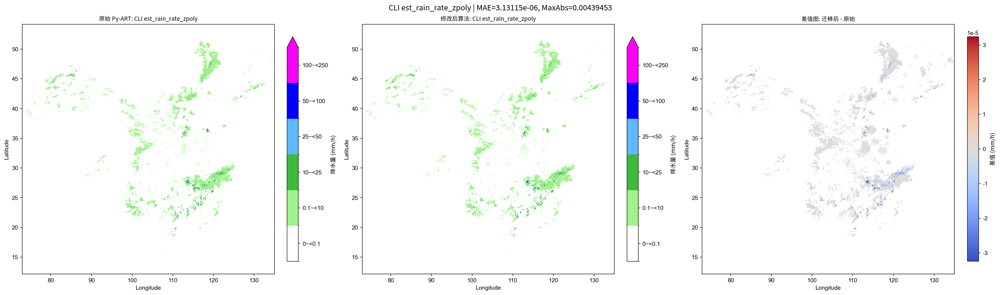

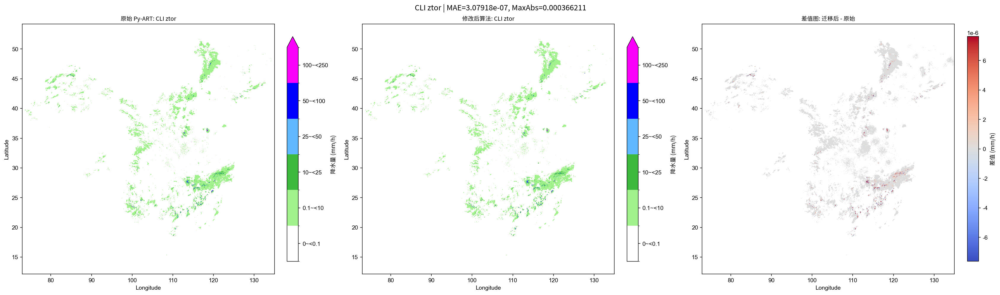

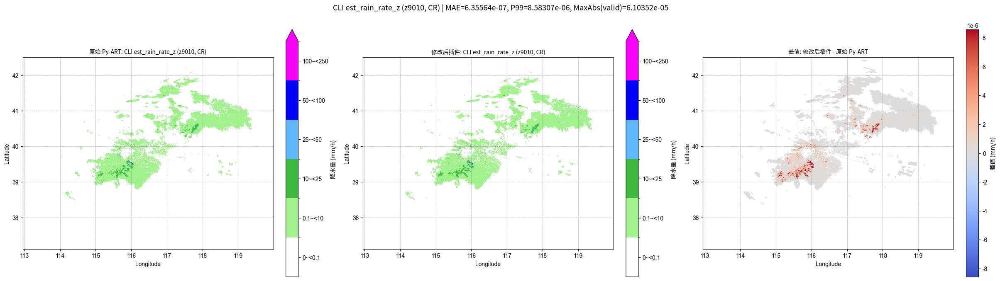

[{'method': 'CLI est_rain_rate_z',
  'mae': 2.7735163143915997e-07,
  'max_abs': 0.00030517578125,
  'vmin': np.float64(0.0),
  'vmax': np.float64(250.0)},
 {'method': 'CLI est_rain_rate_zpoly',
  'mae': 3.131149242108222e-06,
  'max_abs': 0.00439453125,
  'vmin': np.float64(0.0),
  'vmax': np.float64(250.0)},
 {'method': 'CLI ztor',
  'mae': 3.079179009546351e-07,
  'max_abs': 0.0003662109375,
  'vmin': np.float64(0.0),
  'vmax': np.float64(250.0)},
 {'method': 'CLI est_rain_rate_z (z9010, CR)',
  'mae': 6.355642767630343e-07,
  'max_abs': 6.103515625e-05,
  'p99_abs': 8.58306884765625e-06,
  'vmin': np.float64(0.0),
  'vmax': np.float64(250.0)}]

In [36]:
cli_z = meb.read_griddata_from_nc(str(cli_z_file), value_name="radar_estimated_rain_rate")
cli_zpoly = meb.read_griddata_from_nc(str(cli_zpoly_file), value_name="radar_estimated_rain_rate")
cli_ztor = meb.read_griddata_from_nc(str(cli_ztor_file), value_name="NWS_primary_prate")

cli_z_data = masked_to_nan(cli_z.values).squeeze().astype(np.float32)
cli_zpoly_data = masked_to_nan(cli_zpoly.values).squeeze().astype(np.float32)
cli_ztor_data = masked_to_nan(cli_ztor.values).squeeze().astype(np.float32)

cli_compare_records = []
cli_compare_records.append(
    plot_latlon_comparison(
        title="CLI est_rain_rate_z",
        original=rain_rate_z_data,
        migrated=cli_z_data,
        lat=achn_lat,
        lon=achn_lon,
    )
)
cli_compare_records.append(
    plot_latlon_comparison(
        title="CLI est_rain_rate_zpoly",
        original=rain_rate_zpoly_data,
        migrated=cli_zpoly_data,
        lat=achn_lat,
        lon=achn_lon,
    )
)
cli_compare_records.append(
    plot_latlon_comparison(
        title="CLI ztor",
        original=rain_rate_ztor_data,
        migrated=cli_ztor_data,
        lat=achn_lat,
        lon=achn_lon,
    )
)

# Z9010：CLI vs Py-ART 原算法（同一 CR 输入、alpha/beta=0.002/0.8）
cli_z9010 = meb.read_griddata_from_nc(
    str(cli_z9010_z_file), value_name="radar_estimated_rain_rate",
)
cli_z9010_at_gates = sample_plugin_result_at_gates(
    cli_z9010,
    cref_target_lat,
    cref_target_lon,
    z9010_cref_gate_lat,
    z9010_cref_gate_lon,
)
z9010_cli_compare_record = plot_radar_lonlat_comparison(
    title="CLI est_rain_rate_z (z9010, CR)",
    original=original_z_z9010_data,
    migrated=cli_z9010_at_gates,
    gate_lat=z9010_cref_gate_lat,
    gate_lon=z9010_cref_gate_lon,
    extent=z9010_compare_extent,
)
cli_compare_records.append(z9010_cli_compare_record)
cli_compare_records


## 插件结果展示



In [37]:
def plot_qpe_business_map(data, lon, lat, title, *, extent=None):
    """绘制 QPE 业务产品图（表1 离散分级色标）。"""
    qpe_cmap, qpe_norm, qpe_ticks, qpe_tick_labels = create_qpe_discrete_cmap()
    if np.ndim(lon) == 1 and np.ndim(lat) == 1:
        lon_plot, lat_plot = np.meshgrid(lon, lat)
    else:
        lon_plot, lat_plot = lon, lat

    fig, ax = plt.subplots(figsize=(13, 10), constrained_layout=True)
    mesh = ax.pcolormesh(lon_plot, lat_plot, data, shading="auto", cmap=qpe_cmap, norm=qpe_norm)
    # 使用 cinrad 的字体获取函数
    fp = FontProperties(fname=get_font_path())
    ax.set_title(title, fontproperties=fp)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal", adjustable="box")
    if extent is not None:
        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
    ax.grid(True, linestyle="--", linewidth=0.6, color="0.45", alpha=0.55)

    cbar = fig.colorbar(mesh, ax=ax, extend="max", pad=0.02)
    cbar.set_ticks(qpe_ticks)
    cbar.set_ticklabels(qpe_tick_labels)
    cbar.set_label("降水量 (mm/h)", fontproperties=fp)
    cbar.ax.tick_params(length=0, labelsize=9)

    plt.show()


### ACHN数据

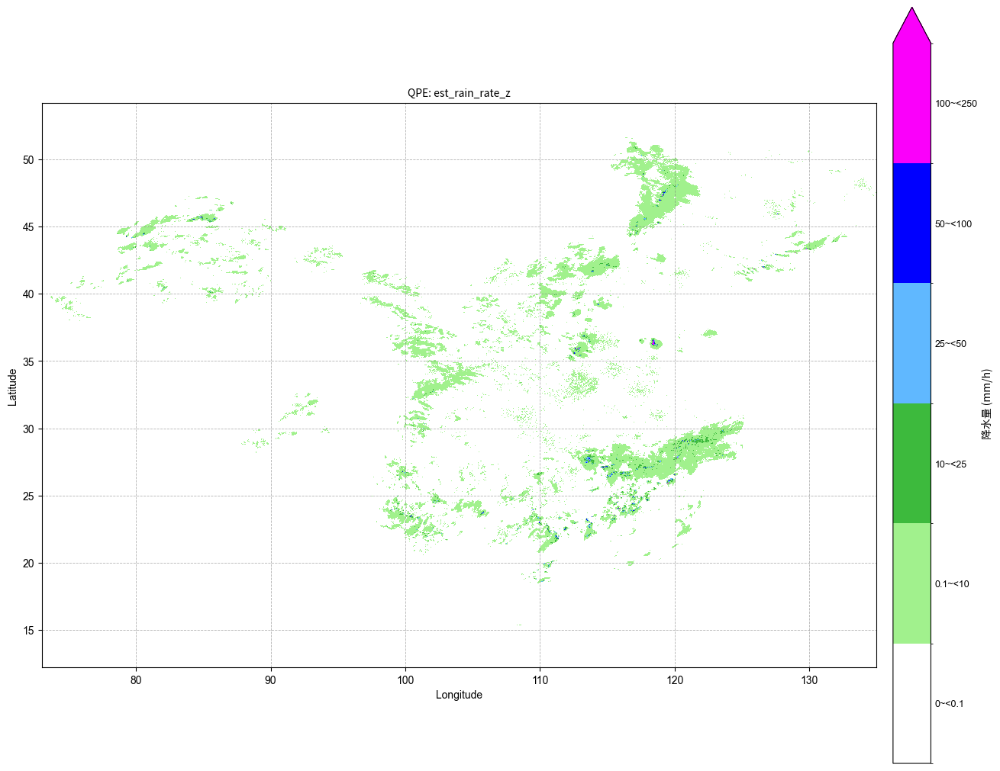

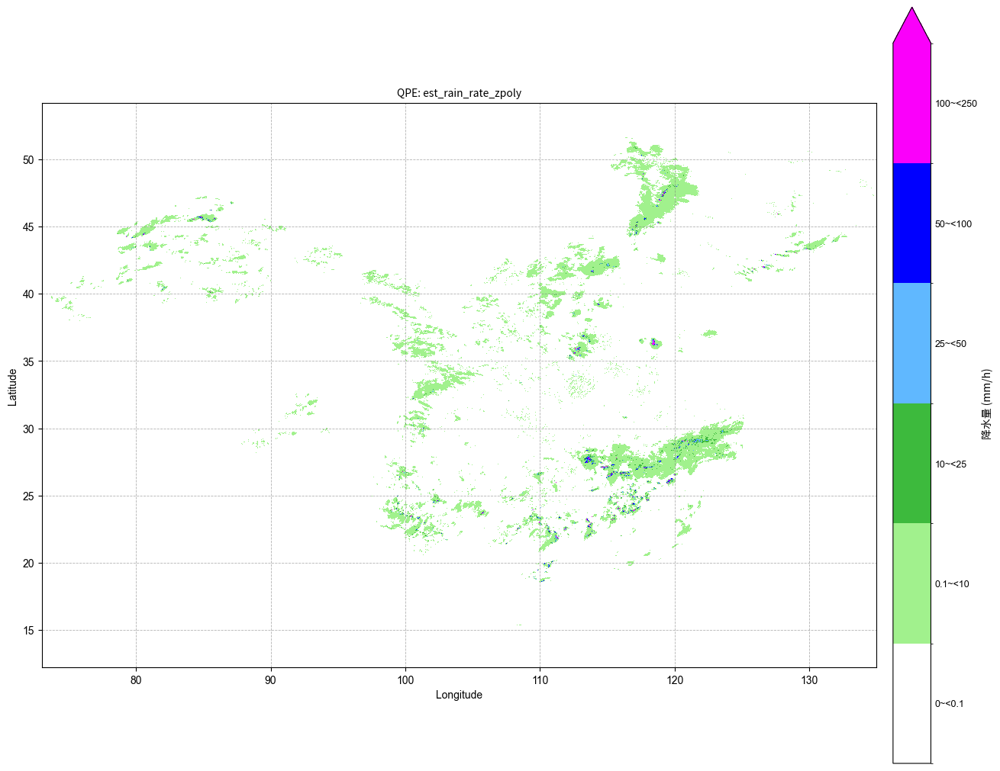

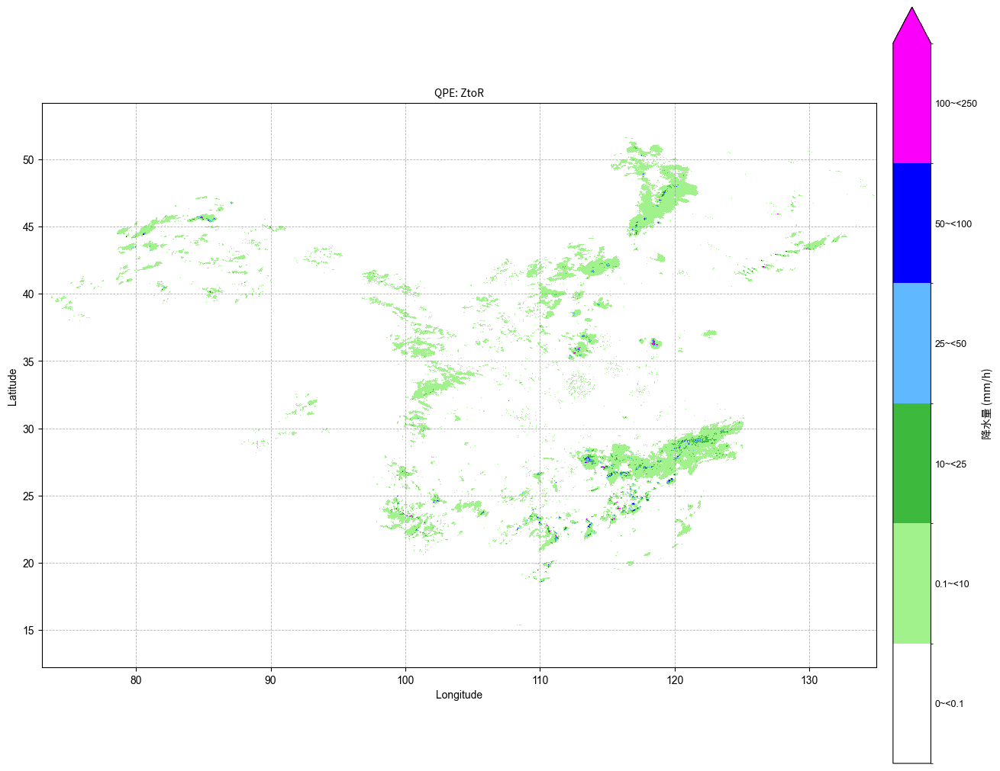

In [38]:
plot_qpe_business_map(plugin_z_data, achn_lon, achn_lat, "QPE: est_rain_rate_z")
plot_qpe_business_map(plugin_zpoly_data, achn_lon, achn_lat, "QPE: est_rain_rate_zpoly")
plot_qpe_business_map(plugin_ztor_data, achn_lon, achn_lat, "QPE: ZtoR")

### Z9010双偏振单站雷达数据

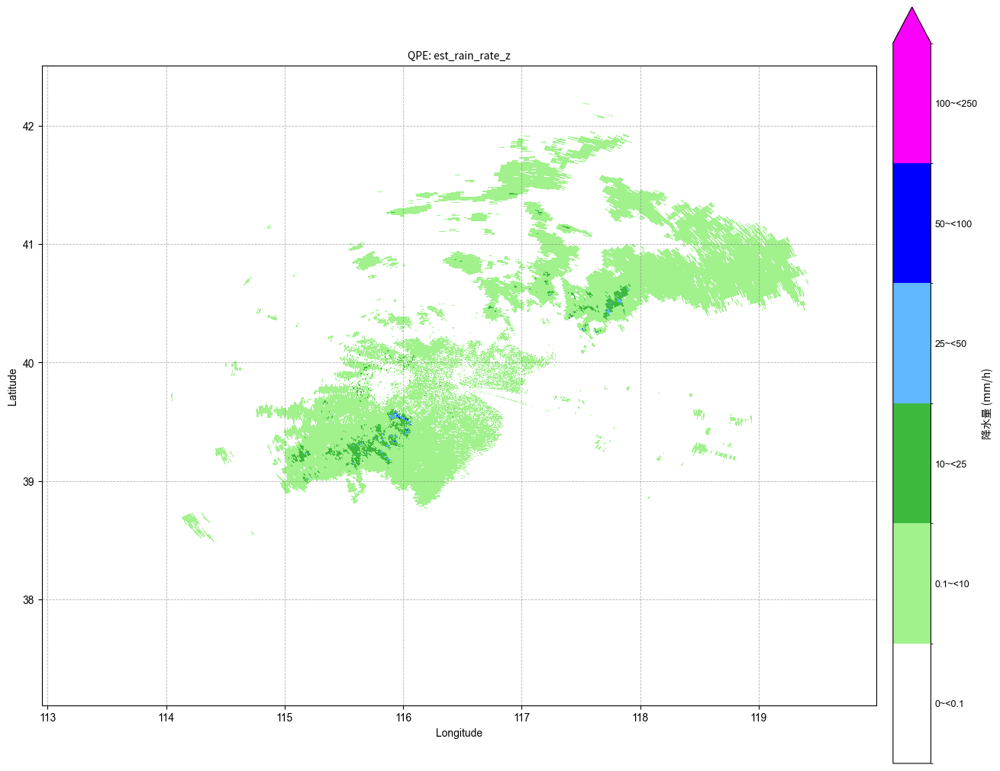

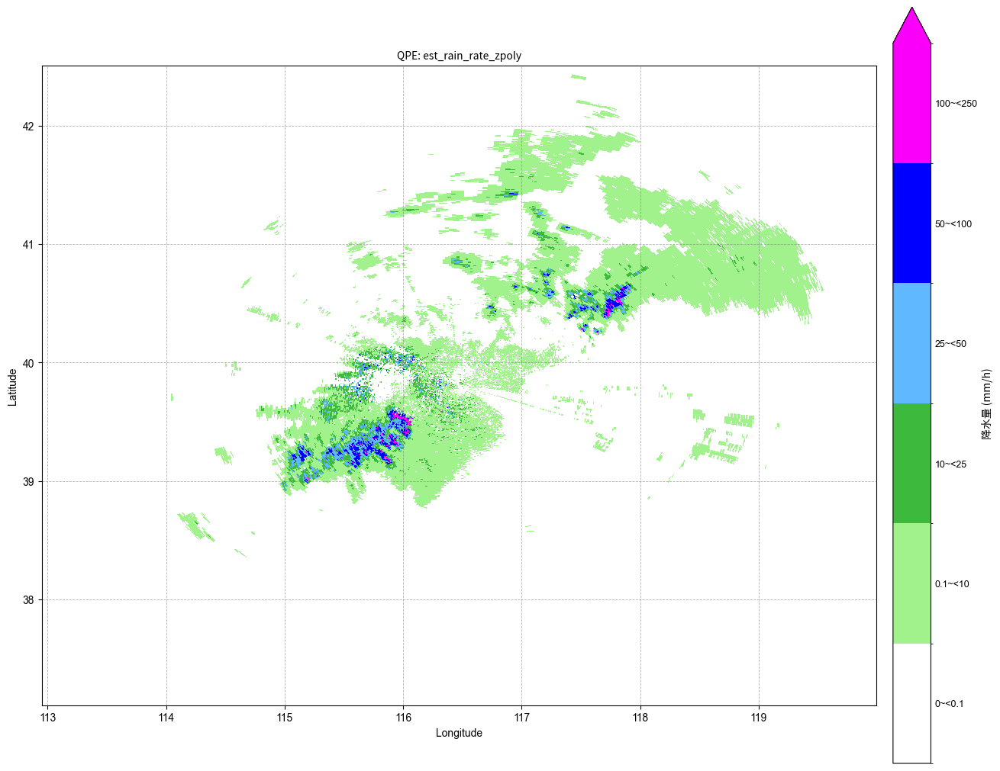

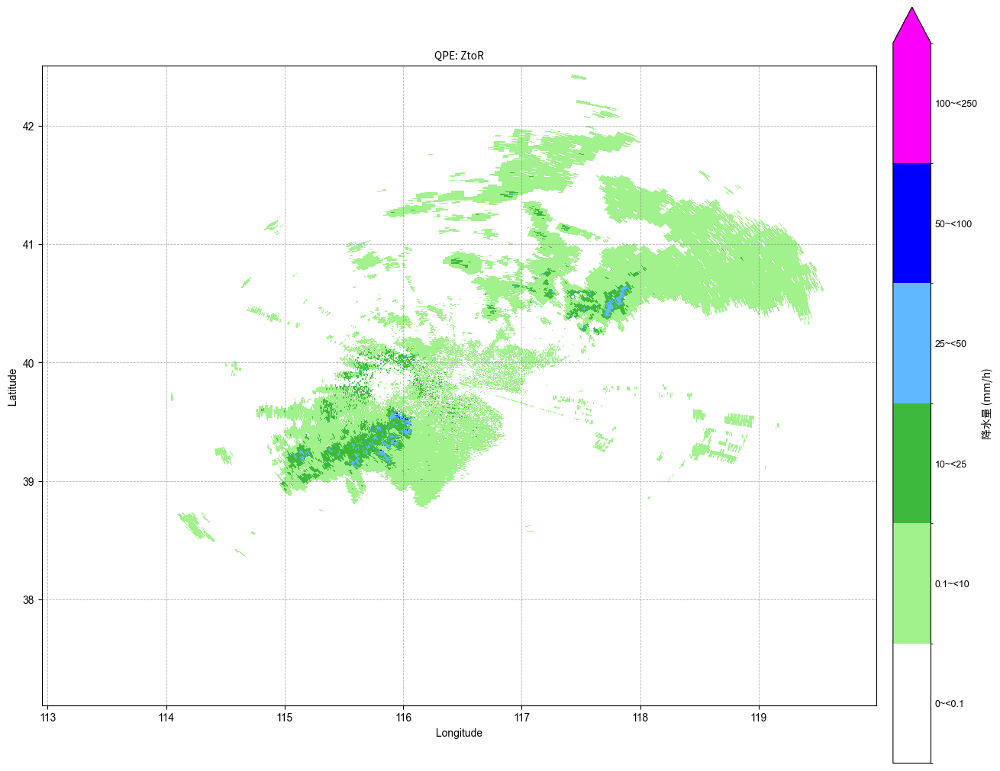

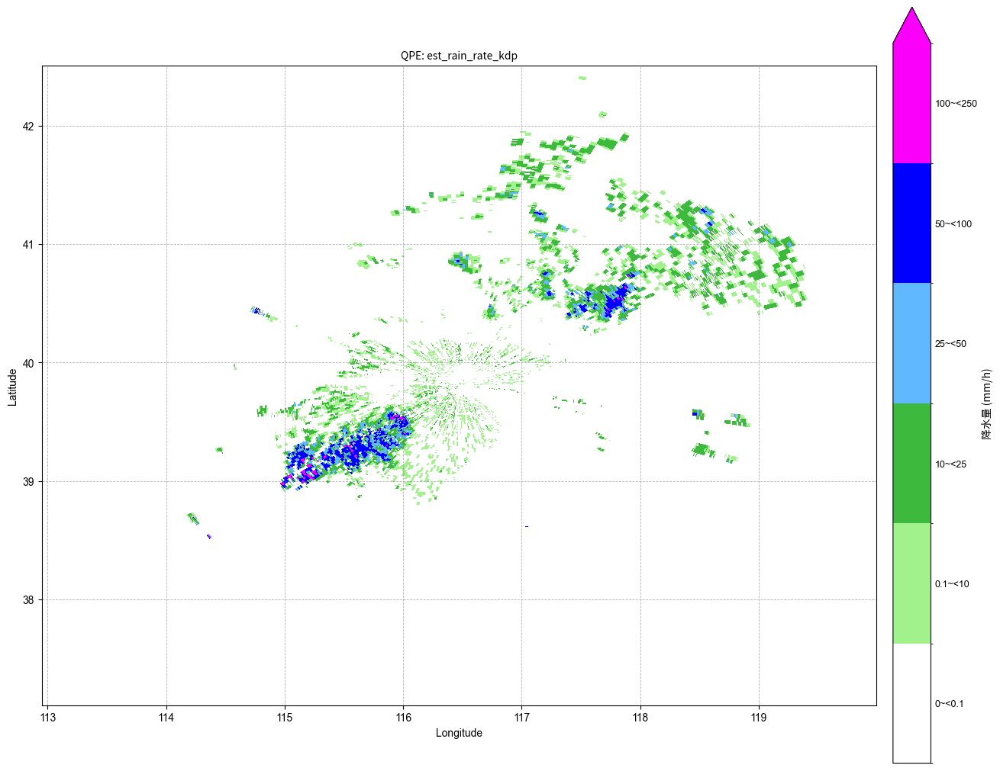

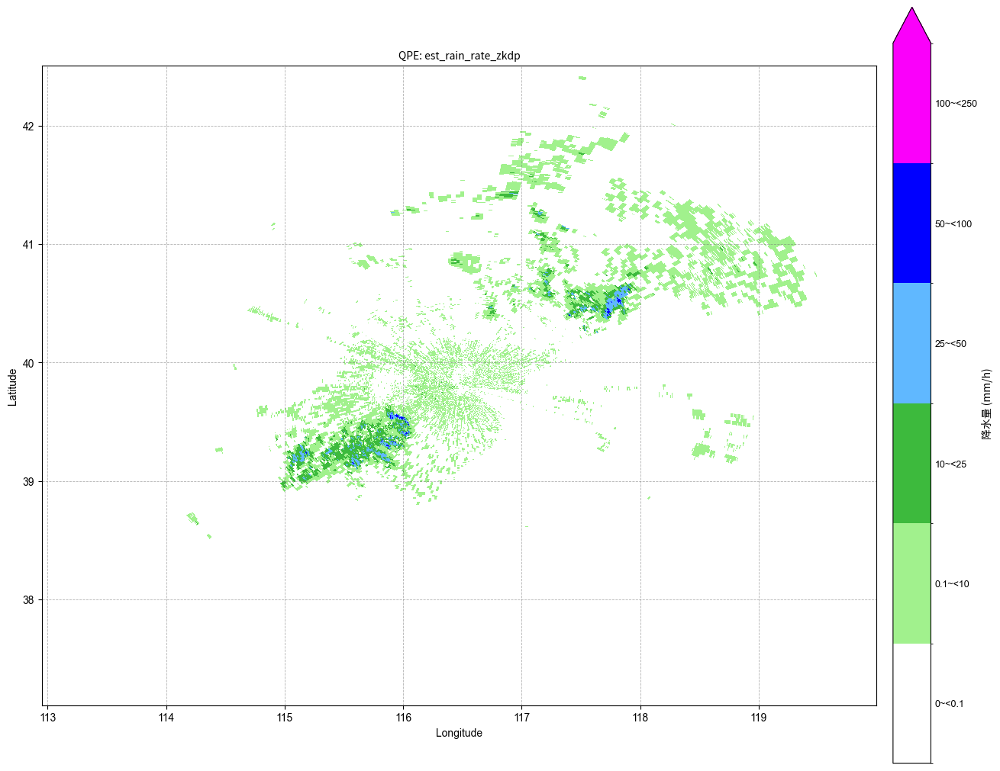

In [39]:
plot_qpe_business_map(
    plugin_z_z9010_at_gates, z9010_cref_gate_lon, z9010_cref_gate_lat,
    "QPE: est_rain_rate_z", extent=z9010_compare_extent,
)
plot_qpe_business_map(
    plugin_zpoly_z9010_at_gates, z9010_cref_gate_lon, z9010_cref_gate_lat,
    "QPE: est_rain_rate_zpoly", extent=z9010_compare_extent,
)
plot_qpe_business_map(
    plugin_ztor_z9010_at_gates, z9010_cref_gate_lon, z9010_cref_gate_lat,
    "QPE: ZtoR", extent=z9010_compare_extent,
)
plot_qpe_business_map(
    plugin_kdp_rr_at_gates, gate_lon, gate_lat,
    "QPE: est_rain_rate_kdp", extent=z9010_compare_extent,
)
plot_qpe_business_map(
    plugin_zkdp_at_gates, gate_lon, gate_lat,
    "QPE: est_rain_rate_zkdp", extent=z9010_compare_extent,
)


### hydro雷达数据

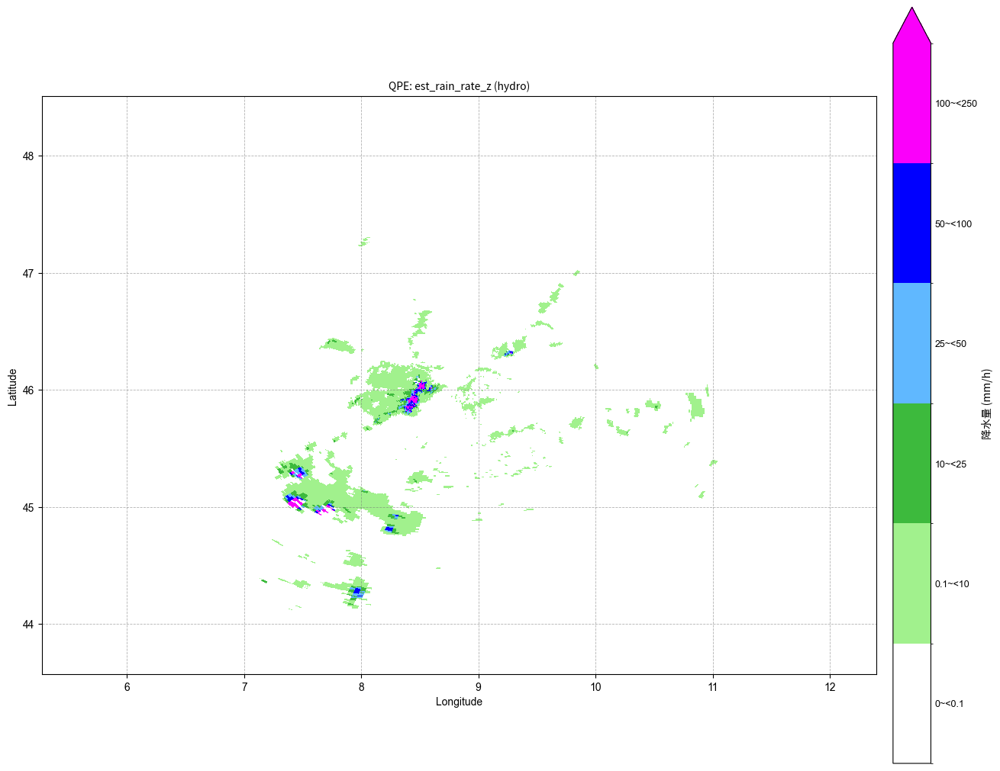

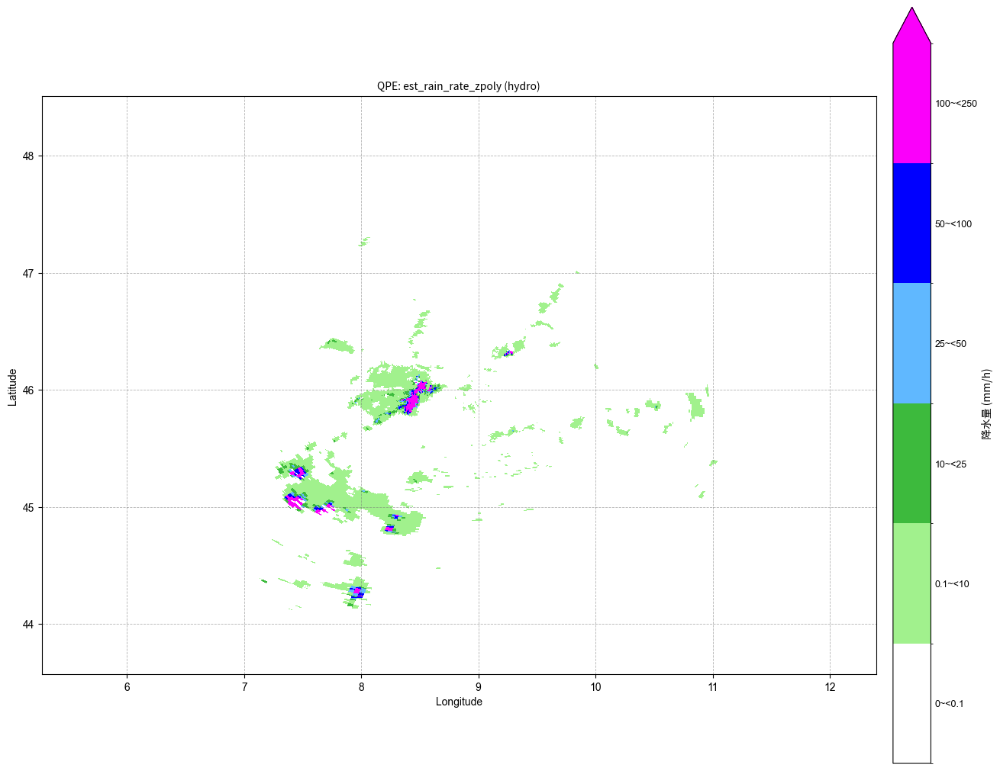

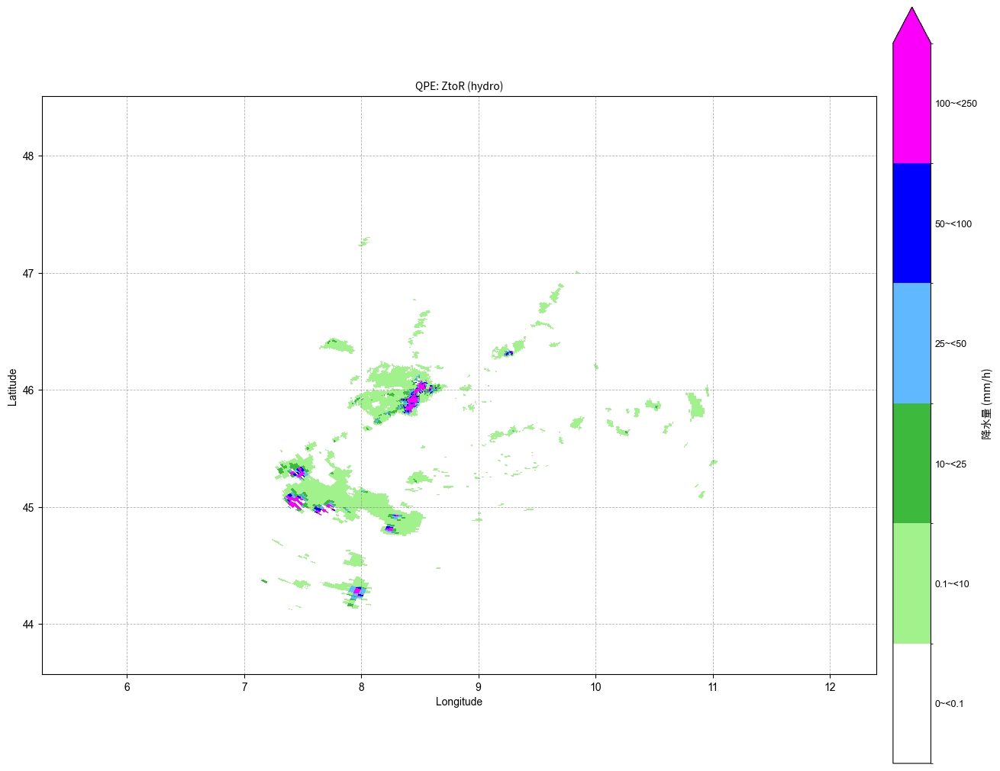

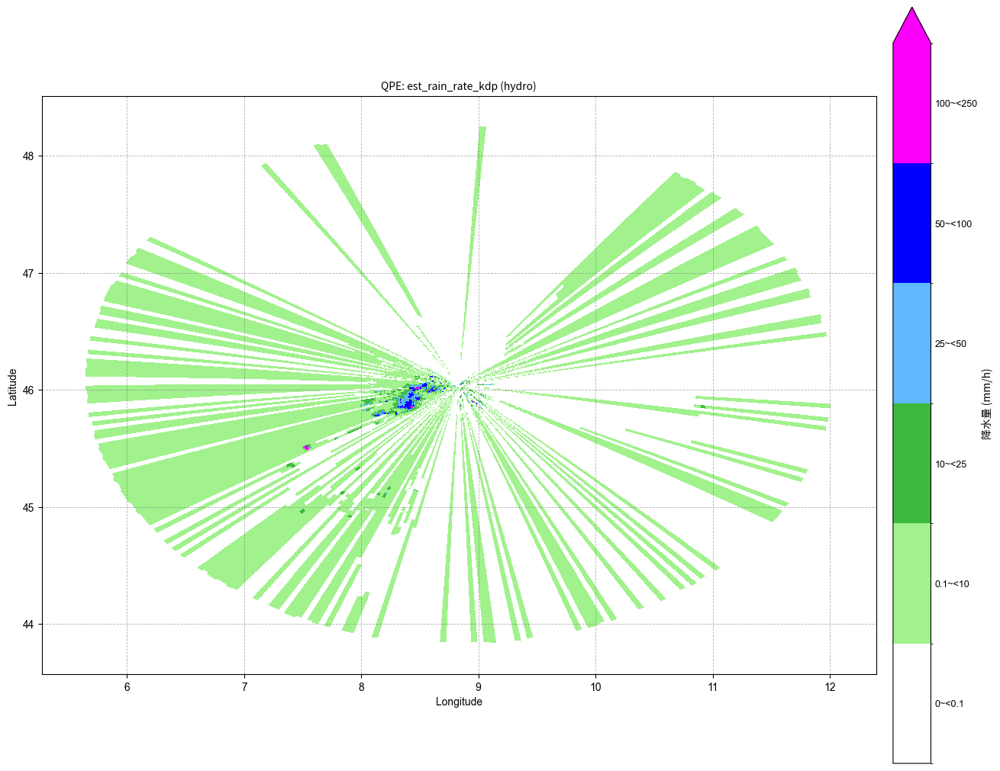

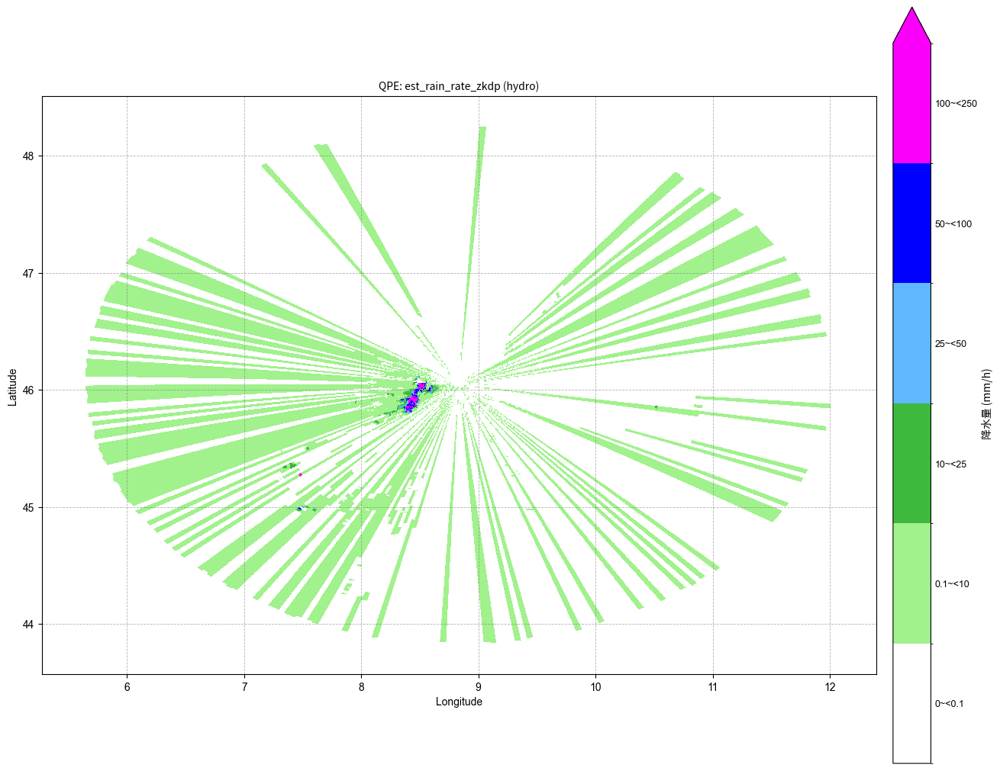

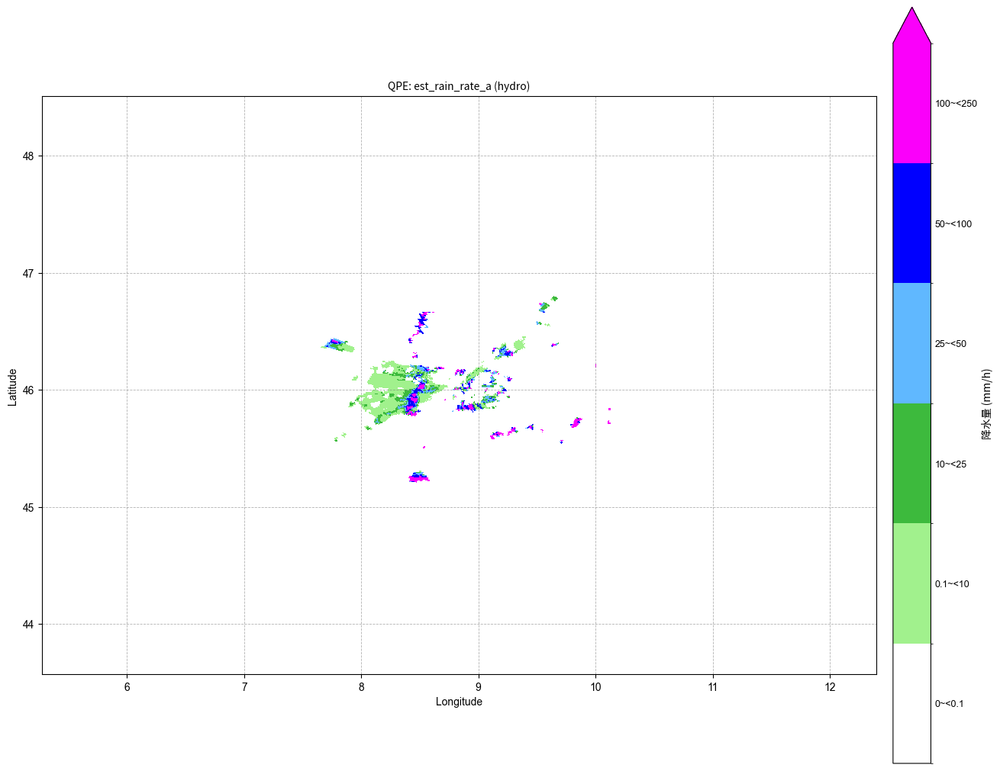

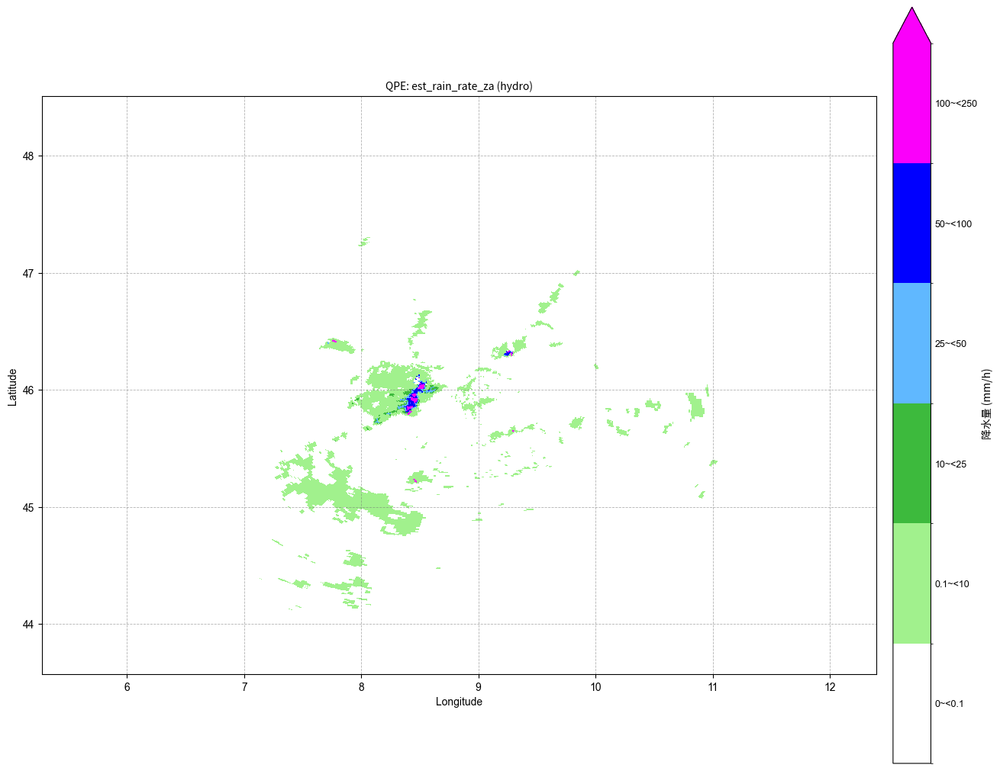

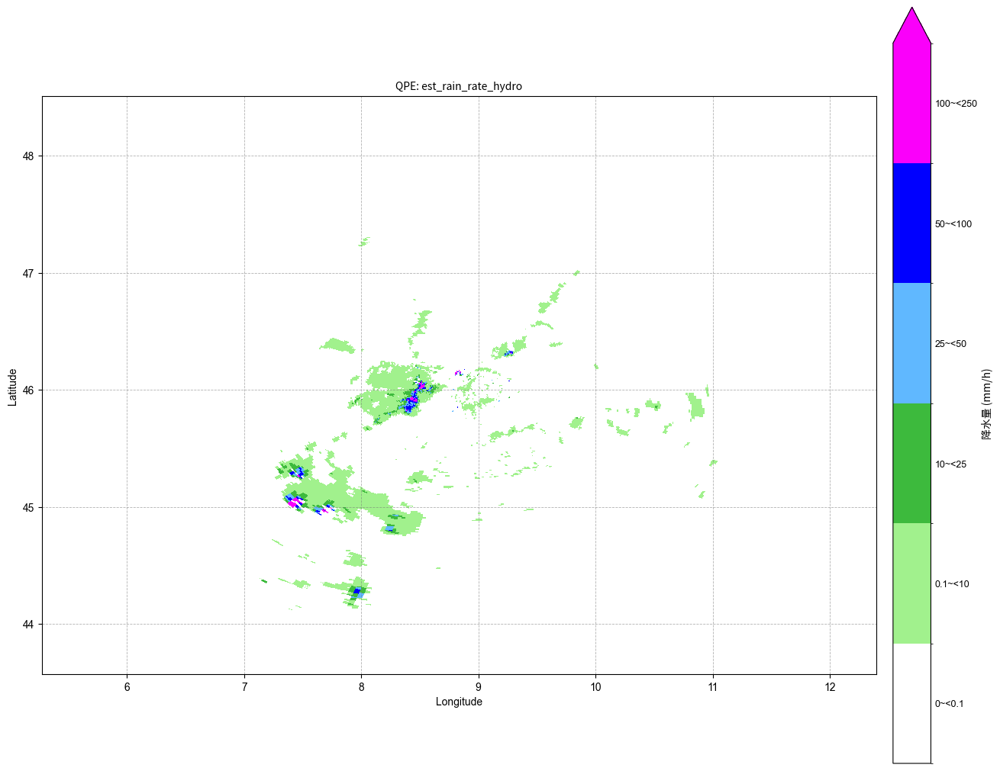

In [40]:
plot_qpe_business_map(
    plugin_z_hydro_at_gates, hydro_gate_lon, hydro_gate_lat,
    "QPE: est_rain_rate_z (hydro)", extent=hydro_extent,
)
plot_qpe_business_map(
    plugin_zpoly_hydro_at_gates, hydro_gate_lon, hydro_gate_lat,
    "QPE: est_rain_rate_zpoly (hydro)", extent=hydro_extent,
)
plot_qpe_business_map(
    plugin_ztor_hydro_at_gates, hydro_gate_lon, hydro_gate_lat,
    "QPE: ZtoR (hydro)", extent=hydro_extent,
)
plot_qpe_business_map(
    plugin_kdp_hydro_at_gates, hydro_gate_lon, hydro_gate_lat,
    "QPE: est_rain_rate_kdp (hydro)", extent=hydro_extent,
)
plot_qpe_business_map(
    plugin_zkdp_hydro_at_gates, hydro_gate_lon, hydro_gate_lat,
    "QPE: est_rain_rate_zkdp (hydro)", extent=hydro_extent,
)
plot_qpe_business_map(
    plugin_a_at_gates, hydro_gate_lon, hydro_gate_lat,
    "QPE: est_rain_rate_a (hydro)", extent=hydro_extent,
)
plot_qpe_business_map(
    plugin_za_at_gates, hydro_gate_lon, hydro_gate_lat,
    "QPE: est_rain_rate_za (hydro)", extent=hydro_extent,
)
plot_qpe_business_map(
    plugin_hydro_at_gates, hydro_gate_lon, hydro_gate_lat,
    "QPE: est_rain_rate_hydro", extent=hydro_extent,
)
